# Movie Recommendation by Low-Rank Factorization: Evaluation, Scaling and Final Analysis (Task 3)

This notebook covers handbook items M4, M5 and M6 and the final test-set evaluation. Shared functions live in `task3.py` (copied from `task2` (Task 2) and the Task 1 part of the group notebook, without the grid search that `task2` runs when executed). Inputs are read from `../data/processed/`, results are written to `outputs/` and figures to `reports_03/`.

## Step 0. Setup and alignment

**Goal.** Before evaluating anything, make sure we are working on exactly the same data and model as Tasks 1 and 2. If the user/movie indexing differed even slightly, every prediction $\hat r_{ij} = u_i^\top v_j$ would combine the wrong rows of $U$ and $V$ and all later results would be meaningless.

**Method.**
1. Load the three processed splits and the saved ALS factors $U \in \mathbb{R}^{943 \times 2}$, $V \in \mathbb{R}^{1682 \times 2}$ (k = 2, lambda = 1.0).
2. Rebuild the index mappings exactly as Task 2 did (sorted ids from the training set) and turn each split into a sparse matrix.
3. Check shapes, the warm-start property of the split, and that no rating appears in two splits.
4. Recompute the validation RMSE from $U$ and $V$. It must match the 0.9265 reported by Task 2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

from task3 import build_index_mappings, df_to_coo, evaluate_metrics_sparse

PROJECT_ROOT = Path("..")                            # repository root (this notebook lives in task3_evaluation/)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"  # shared inputs from Tasks 1 and 2 (read only)
OUTPUT_DIR = Path("outputs")                         # everything this notebook produces
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

U_best = np.load(PROCESSED_DIR / "U_best.npy")
V_best = np.load(PROCESSED_DIR / "V_best.npy")

print("Train:", train.shape, "| Validation:", validation.shape, "| Test:", test.shape)
print("U_best:", U_best.shape, "| V_best:", V_best.shape)

# Row counts documented by Task 1
assert len(train) == 80031 and len(validation) == 9987 and len(test) == 9982

Train: (80031, 5) | Validation: (9987, 5) | Test: (9982, 5)
U_best: (943, 2) | V_best: (1682, 2)


In [2]:
# Same mapping as Task 2: sorted ids from TRAIN -> 0-based positions.
# Row i of U_best is the user unique_users[i], row j of V_best is the movie unique_movies[j].
unique_users, unique_movies, user_to_idx, movie_to_idx = build_index_mappings(train)
n_users, n_movies = len(unique_users), len(unique_movies)

R_train_coo = df_to_coo(train, user_to_idx, movie_to_idx)
R_val_coo = df_to_coo(validation, user_to_idx, movie_to_idx)
R_test_coo = df_to_coo(test, user_to_idx, movie_to_idx)

print(f"Users: {n_users}, Movies: {n_movies}")
print(f"Observed entries -> Train: {R_train_coo.nnz}, Validation: {R_val_coo.nnz}, Test: {R_test_coo.nnz}")
print(f"Train density: {R_train_coo.nnz / (n_users * n_movies):.4%}")

# The factor matrices must have one row per user / movie of the mapping
assert U_best.shape == (n_users, 2) and V_best.shape == (n_movies, 2)

Users: 943, Movies: 1682
Observed entries -> Train: 80031, Validation: 9987, Test: 9982
Train density: 5.0457%


In [3]:
# Warm start: every user and movie of validation/test must exist in train,
# otherwise .map() would give NaN and the model would have no factor vector for it.
for name, df in [("validation", validation), ("test", test)]:
    assert df["user_id"].isin(user_to_idx).all(), f"unseen user in {name}"
    assert df["movie_id"].isin(movie_to_idx).all(), f"unseen movie in {name}"

# No (user, movie) pair may appear in two splits, otherwise we would evaluate on training data
pairs = {name: set(zip(df["user_id"], df["movie_id"]))
         for name, df in [("train", train), ("validation", validation), ("test", test)]}
assert not pairs["train"] & pairs["validation"]
assert not pairs["train"] & pairs["test"]
assert not pairs["validation"] & pairs["test"]
print("Warm-start and disjointness checks passed.")

Warm-start and disjointness checks passed.


In [4]:
# Reproduce Task 2's numbers from the saved factors: r_hat_ij = u_i . v_j on observed entries only
train_rmse, train_mae = evaluate_metrics_sparse(R_train_coo, U_best, V_best)
val_rmse, val_mae = evaluate_metrics_sparse(R_val_coo, U_best, V_best)
print(f"Train RMSE: {train_rmse:.4f} | Train MAE: {train_mae:.4f}")
print(f"Val   RMSE: {val_rmse:.4f} | Val   MAE: {val_mae:.4f}")

# Compare with the saved tuning table and with the last iteration of the convergence history
tuning = pd.read_csv(PROCESSED_DIR / "als_hyperparameter_tuning.csv")
best_row = tuning[(tuning["k"] == 2) & (tuning["lambda"] == 1.0)].iloc[0]
history = pd.read_csv(PROCESSED_DIR / "als_best_convergence_history.csv")
print(f"Tuning CSV  -> Train RMSE: {best_row['Train_RMSE']:.4f} | Val RMSE: {best_row['Val_RMSE']:.4f} | Val MAE: {best_row['Val_MAE']:.4f}")
print(f"History CSV -> Val RMSE at iteration {history['iter'].iloc[-1]}: {history['val_rmse'].iloc[-1]:.4f}")

assert np.isclose(val_rmse, best_row["Val_RMSE"], atol=1e-6)
assert np.isclose(val_mae, best_row["Val_MAE"], atol=1e-6)
assert np.isclose(train_rmse, best_row["Train_RMSE"], atol=1e-6)
assert round(val_rmse, 4) == 0.9265
print("Saved factors reproduce the reported validation RMSE.")

# The test set stays untouched until Step 2

Train RMSE: 0.8627 | Train MAE: 0.6797
Val   RMSE: 0.9265 | Val   MAE: 0.7257
Tuning CSV  -> Train RMSE: 0.8627 | Val RMSE: 0.9265 | Val MAE: 0.7257
History CSV -> Val RMSE at iteration 15: 0.9265
Saved factors reproduce the reported validation RMSE.


### Step 0 results

- The splits have the expected sizes (80,031 / 9,987 / 9,982 ratings) over 943 users and 1,682 movies. The training matrix is very sparse (about 5% of the entries observed), which is why every metric is computed only on the observed set $\Omega$ and never on the full matrix.
- The split is warm-start: every user and movie in validation and test also appears in train, so each one has a factor vector. No (user, movie) pair is shared between splits, so there is no leakage.
- With the rebuilt mapping, $U_{best} V_{best}^\top$ reproduces Task 2's train and validation errors exactly (validation RMSE 0.9265, MAE 0.7257). This confirms that the rows of $U$ and $V$ line up with our user and movie indices, so we can reuse these factors in the next steps.
- We have not looked at the test set yet. It will be used only once, in Step 2, after the model choice is final.

## Step 1. Learning curves and tuning visualization (M4)

**Goal.** Check whether Task 2's choice of k = 2, lambda = 1.0 holds up. In the original grid, 32 of 36 runs stopped at `max_iter = 15` before reaching the tolerance. Small k converges in fewer iterations, so an early stop can favour small k for the wrong reason.

**Method.**
- ALS minimizes $\sum_{(i,j) \in \Omega} (r_{ij} - u_i^\top v_j)^2 + \lambda (\|U\|_F^2 + \|V\|_F^2)$. Each half step fixes one factor and solves, for every row, the $k \times k$ symmetric positive definite system $(F_{\Omega_i}^\top F_{\Omega_i} + \lambda I_k)\, x = F_{\Omega_i}^\top r_{\Omega_i}$ with Cholesky. Each half step is an exact minimization over one block, so the objective never increases. The algorithm stops when the relative change of train RMSE drops below `tol = 1e-4`, or at `max_iter`.
- We time one run, re-run the grid with `max_iter = 50` if it is cheap enough, and record whether each run reached `tol` (converged) or hit `max_iter`.
- We compare the old and new validation RMSE heatmaps on the same color scale, and plot train and validation RMSE per iteration for five configurations.
- **Selection rule:** among runs that converged, take the lowest validation RMSE. If several runs are within 0.002 of that minimum, take the one with the smallest k (simpler model, fewer parameters).

In [5]:
import time
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from task3 import fit_als

REPORTS_DIR = Path("reports_03")
REPORTS_DIR.mkdir(exist_ok=True)

K_GRID = [2, 5, 10, 20, 30, 50]
LAMBDA_GRID = [0.1, 1.0, 5.0, 10.0, 15.0, 25.0]
MAX_ITER = 50
TOL = 1e-4
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"

# Time the most expensive configuration (largest k, weakest regularization, so it never stops early).
# 36 times this value is an upper bound for the whole grid.
start = time.perf_counter()
_, _, hist = fit_als(R_train_coo, R_val_coo, k=50, lambda_reg=0.1, max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE, verbose=False)
one_run = time.perf_counter() - start
print(f"One run (k=50, lambda=0.1, {len(hist)} iterations): {one_run:.1f} s")
print(f"Upper bound for the 6x6 grid: {36 * one_run / 60:.1f} min")

One run (k=50, lambda=0.1, 50 iterations): 4.7 s
Upper bound for the 6x6 grid: 2.8 min


In [6]:
def has_converged(history, tol=TOL):
    # Same criterion as inside fit_als: relative change of train RMSE at the last iteration
    rmse = history["train_rmse"].to_numpy()
    return len(rmse) > 1 and abs(rmse[-2] - rmse[-1]) / rmse[-2] < tol

# The grid is cheap (see above), so we re-run all 36 configurations with max_iter = 50
records, histories, factors = [], {}, {}
start = time.perf_counter()
for k in K_GRID:
    for lam in LAMBDA_GRID:
        U, V, hist = fit_als(R_train_coo, R_val_coo, k=k, lambda_reg=lam, max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE, verbose=False)
        histories[(k, lam)] = hist
        factors[(k, lam)] = (U, V)
        records.append({
            "k": k, "lambda": lam,
            "Train_RMSE": hist["train_rmse"].iloc[-1],
            "Val_RMSE": hist["val_rmse"].iloc[-1],
            "Val_MAE": hist["val_mae"].iloc[-1],
            "Iterations": len(hist),
            "Converged": has_converged(hist),
        })
print(f"Grid with max_iter={MAX_ITER} completed in {time.perf_counter() - start:.1f} s")

tuning_50 = pd.DataFrame(records).sort_values(["Val_RMSE", "k"]).reset_index(drop=True)
tuning_50.to_csv(OUTPUT_DIR / "eval_tuning_50iter.csv", index=False)

# Original 15-iteration grid. "Iterations < 15" is not enough: a run can reach tol exactly at iteration 15.
# ALS with a fixed seed is deterministic, so the first 15 iterations are identical in both grids:
# a 15-iteration run converged iff the 50-iteration run stopped at iteration 15 or earlier.
tuning_15 = tuning.merge(tuning_50[["k", "lambda", "Iterations"]], on=["k", "lambda"], suffixes=("", "_50"))
assert (tuning_15.loc[tuning_15["Iterations"] < 15, "Iterations"] == tuning_15.loc[tuning_15["Iterations"] < 15, "Iterations_50"]).all()
tuning_15["Converged"] = tuning_15["Iterations_50"] <= 15

print(f"Converged runs: {tuning_15['Converged'].sum()}/36 with max_iter=15, {tuning_50['Converged'].sum()}/36 with max_iter=50")
tuning_50.head(10).round(4)

Grid with max_iter=50 completed in 65.3 s
Converged runs: 4/36 with max_iter=15, 25/36 with max_iter=50


,k,lambda,Train_RMSE,Val_RMSE,Val_MAE,Iterations,Converged
0,2,1.0,0.8610,0.9227,0.7224,23,True
1,2,0.1,0.8585,0.9345,0.7268,31,True
2,2,5.0,0.8822,0.9355,0.7343,17,True
3,5,5.0,0.8115,0.9375,0.7286,19,True
4,5,1.0,0.7722,0.9464,0.7310,35,True
5,5,10.0,0.8641,0.9588,0.7484,15,True
6,10,10.0,0.8067,0.9652,0.7530,26,True
7,10,5.0,0.7280,0.9656,0.7493,26,True
8,2,10.0,0.9173,0.9661,0.7588,14,True
9,20,10.0,0.7311,0.9774,0.7626,32,True


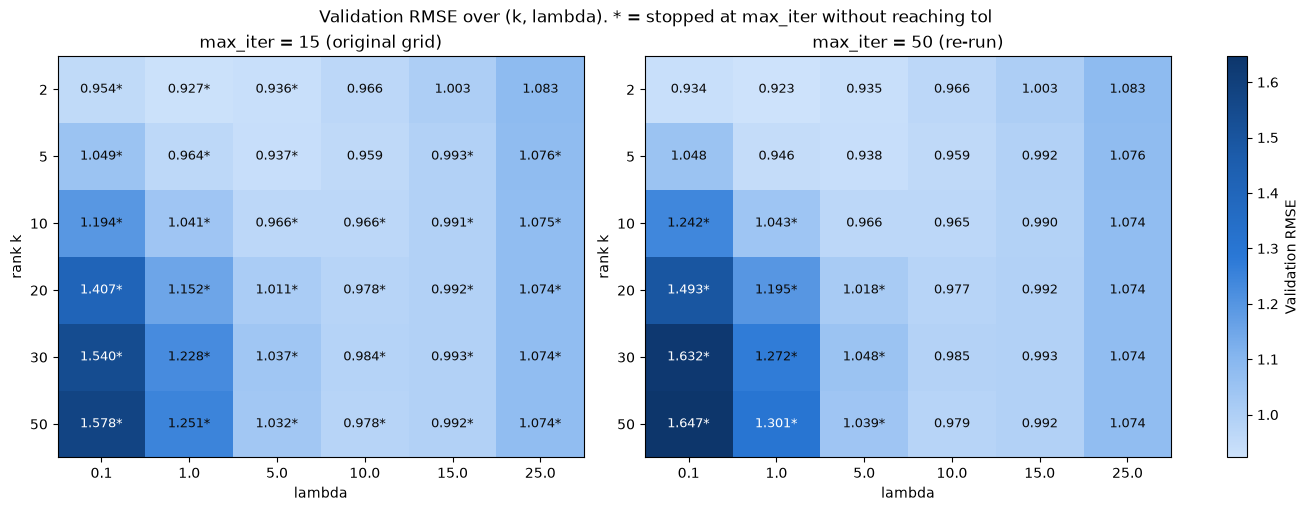

In [7]:
# Sequential single-hue scale (light = low RMSE = good, dark = high RMSE), shared by both panels
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
vmin = min(tuning_15["Val_RMSE"].min(), tuning_50["Val_RMSE"].min())
vmax = max(tuning_15["Val_RMSE"].max(), tuning_50["Val_RMSE"].max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, df, title in [(axes[0], tuning_15, "max_iter = 15 (original grid)"), (axes[1], tuning_50, "max_iter = 50 (re-run)")]:
    rmse = df.pivot(index="k", columns="lambda", values="Val_RMSE").loc[K_GRID, LAMBDA_GRID]
    conv = df.pivot(index="k", columns="lambda", values="Converged").loc[K_GRID, LAMBDA_GRID]
    im = ax.imshow(rmse.to_numpy(), cmap=blues, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(len(K_GRID)):
        for j in range(len(LAMBDA_GRID)):
            value = rmse.iloc[i, j]
            # '*' marks runs that hit max_iter without reaching tol
            label = f"{value:.3f}" + ("" if conv.iloc[i, j] else "*")
            ax.text(j, i, label, ha="center", va="center", fontsize=9,
                    color="white" if value > (vmin + vmax) / 2 else "#0b0b0b")
    ax.set_xticks(range(len(LAMBDA_GRID)), LAMBDA_GRID)
    ax.set_yticks(range(len(K_GRID)), K_GRID)
    ax.set_xlabel("lambda")
    ax.set_ylabel("rank k")
    ax.set_title(title)
fig.colorbar(im, ax=axes, label="Validation RMSE")
fig.suptitle("Validation RMSE over (k, lambda). * = stopped at max_iter without reaching tol")
fig.savefig(REPORTS_DIR / "step1_heatmaps_val_rmse.png", dpi=150)
plt.show()

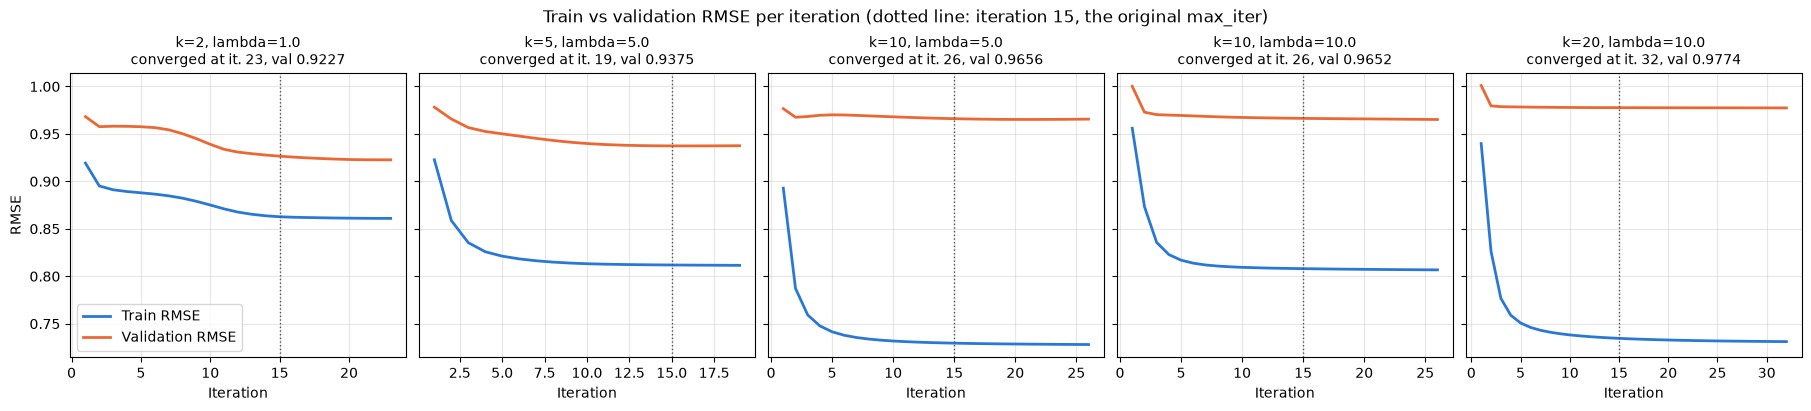

lambda,0.1,1.0,5.0,10.0,15.0,25.0
k,,,,,,
2,31,23,17,14,12,14
5,43,35,19,15,17,19
10,50,50,26,26,21,19
20,50,50,50,32,24,19
30,50,50,50,32,24,17
50,50,50,50,32,25,16


In [8]:
# Learning curves for the five configurations listed in the plan
curve_configs = [(2, 1.0), (5, 5.0), (10, 5.0), (10, 10.0), (20, 10.0)]

fig, axes = plt.subplots(1, len(curve_configs), figsize=(18, 4), sharey=True, constrained_layout=True)
for ax, (k, lam) in zip(axes, curve_configs):
    hist = histories[(k, lam)]
    ax.plot(hist["iter"], hist["train_rmse"], color=TRAIN_COLOR, linewidth=2, label="Train RMSE")
    ax.plot(hist["iter"], hist["val_rmse"], color=VAL_COLOR, linewidth=2, label="Validation RMSE")
    ax.axvline(15, color="#52514e", linestyle=":", linewidth=1)  # where the original grid stopped
    status = f"converged at it. {len(hist)}" if has_converged(hist) else f"hit max_iter={MAX_ITER}"
    ax.set_title(f"k={k}, lambda={lam}\n{status}, val {hist['val_rmse'].iloc[-1]:.4f}", fontsize=10)
    ax.set_xlabel("Iteration")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE")
axes[0].legend()
fig.suptitle("Train vs validation RMSE per iteration (dotted line: iteration 15, the original max_iter)")
fig.savefig(REPORTS_DIR / "step1_learning_curves.png", dpi=150)
plt.show()

# Converged or not, for every run of the new grid
tuning_50.pivot(index="k", columns="lambda", values="Iterations").loc[K_GRID, LAMBDA_GRID]

In [9]:
# Selection rule: lowest validation RMSE among converged runs, prefer smaller k within 0.002
SELECTION_MARGIN = 0.002
converged = tuning_50[tuning_50["Converged"]]
best_val = converged["Val_RMSE"].min()
candidates = converged[converged["Val_RMSE"] <= best_val + SELECTION_MARGIN].sort_values(["k", "Val_RMSE"])
final = candidates.iloc[0]
K_FINAL, LAMBDA_FINAL = int(final["k"]), float(final["lambda"])

print(f"Lowest converged validation RMSE: {best_val:.4f}")
print("Candidates within 0.002:")
print(candidates[["k", "lambda", "Val_RMSE", "Val_MAE", "Iterations"]].round(4).to_string(index=False))

# Check that no non-converged run beats the chosen one (it would only be excluded by the rule)
better_unconverged = tuning_50[~tuning_50["Converged"] & (tuning_50["Val_RMSE"] < final["Val_RMSE"])]
print(f"Non-converged runs with lower validation RMSE: {len(better_unconverged)}")
print(f"\nFinal model: k = {K_FINAL}, lambda = {LAMBDA_FINAL}, Val RMSE = {final['Val_RMSE']:.4f}, Val MAE = {final['Val_MAE']:.4f}")

Lowest converged validation RMSE: 0.9227
Candidates within 0.002:
 k  lambda  Val_RMSE  Val_MAE  Iterations
 2     1.0    0.9227   0.7224          23
Non-converged runs with lower validation RMSE: 0

Final model: k = 2, lambda = 1.0, Val RMSE = 0.9227, Val MAE = 0.7224


In [10]:
# Refit the final model from scratch (same seed) and save it under new names.
# U_best.npy / V_best.npy from Task 2 are left untouched.
U_final, V_final, history_final = fit_als(R_train_coo, R_val_coo, k=K_FINAL, lambda_reg=LAMBDA_FINAL,
                                          max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE, verbose=False)
val_rmse_final, val_mae_final = evaluate_metrics_sparse(R_val_coo, U_final, V_final)
print(f"Refit: {len(history_final)} iterations, Val RMSE {val_rmse_final:.4f}, Val MAE {val_mae_final:.4f}")

# ALS with a fixed seed is deterministic, so the refit must match the grid run
assert np.isclose(val_rmse_final, final["Val_RMSE"], atol=1e-10)

np.save(OUTPUT_DIR / "eval_U_final.npy", U_final)
np.save(OUTPUT_DIR / "eval_V_final.npy", V_final)
print("Saved eval_U_final.npy", U_final.shape, "and eval_V_final.npy", V_final.shape)

Refit: 23 iterations, Val RMSE 0.9227, Val MAE 0.7224
Saved eval_U_final.npy (943, 2) and eval_V_final.npy (1682, 2)


### Step 1 results

**Cost.** One ALS run takes about 1 to 5 seconds (worst case k = 50), so the full 6 x 6 grid with `max_iter = 50` ran in about a minute. That let us re-run all 36 configurations instead of only five.

**Convergence.** With `max_iter = 15` only 4 of 36 runs reached the tolerance (k = 5, lambda = 10 reached `tol` exactly at iteration 15, so it counts as converged). With `max_iter = 50`, 25 of 36 runs converge. The 11 runs that still hit the limit are all in the bottom-left corner of the heatmap (k >= 10 with lambda <= 1, and k >= 20 with lambda = 5). This is the overfitting region: weak regularization relative to the number of parameters, where the problem is poorly conditioned and ALS moves slowly.

**Heatmaps.** Extra iterations change the converged region very little (differences in the third decimal). In the overfitting corner, validation RMSE actually gets *worse* with more iterations (for example k = 50, lambda = 0.1 goes from 1.578 to 1.647). Stopping at 15 iterations acted as an accidental early-stopping regularizer there. The overall shape is the same in both grids: a valley along the diagonal where larger k needs larger lambda, with the minimum at small k and moderate lambda.

**Learning curves.** Train RMSE always decreases, as expected from a block coordinate descent method where each step solves an exact least squares problem. Validation RMSE behaves differently. For k >= 10 it flattens after about 5 iterations while train RMSE keeps falling, so the train/validation gap grows with k (about 0.06 for k = 2, about 0.24 for k = 10 or k = 20). The extra rank fits noise in the observed ratings instead of structure that generalizes. k = 2, lambda = 1.0 converges slowly: its validation error was still decreasing at iteration 15 and stabilizes only around iteration 20.

**Final model.** Applying the rule (lowest converged validation RMSE, prefer smaller k within 0.002) gives **k = 2, lambda = 1.0** with validation RMSE **0.9227** and MAE **0.7224** (converged at iteration 23). The second best converged run (k = 2, lambda = 0.1, 0.9345) is 0.012 worse, far outside the 0.002 margin, so the choice is not borderline. No non-converged run does better. The concern that the 15-iteration limit unfairly favoured k = 2 is therefore not supported: giving every model enough iterations confirms the same configuration and slightly improves it (0.9265 -> 0.9227). The refitted factors are saved as `eval_U_final.npy` and `eval_V_final.npy` and will be used from Step 2 onward.

**Link to the guiding question.** Larger k always reaches a lower *training* error (k = 50, lambda = 0.1: train RMSE about 0.17) but a much higher validation error. A lower reconstruction error on observed ratings does not even guarantee better rating prediction on held-out ratings, before we look at ranking quality in Step 3.

## Step 2. Final rating accuracy on the test set

**Goal.** Measure how well each model predicts ratings it has never seen, on the test set. This is the first and only time the test set is used. All choices (baseline definitions, SVD rank, ALS k and lambda) were made on validation, so the test error is an unbiased estimate of generalization error.

**Method.**
- **Mean baselines** (Task 1): predict the global mean, the user's mean or the movie's mean, all computed on train.
- **Naive SVD** (Task 1): fill missing entries with 0, compute the full SVD $R_0 = U \Sigma V^\top$ and keep the top k singular triplets. By the Eckart-Young theorem, $U_k \Sigma_k V_k^\top$ is the best rank-k approximation of $R_0$ in Frobenius norm. But $R_0$ treats about 95% of unknown ratings as real zeros, so the approximation is pulled toward 0. The rank k is chosen on validation with Task 1's `find_best_k`.
- **Regularized ALS** (Step 1 final model, k = 2, lambda = 1.0): $\hat r_{ij} = u_i^\top v_j$, fitted only on the observed entries.
- For each model we report RMSE $= \sqrt{\frac{1}{|\Omega_{test}|}\sum (\hat r_{ij} - r_{ij})^2}$ and MAE $= \frac{1}{|\Omega_{test}|}\sum |\hat r_{ij} - r_{ij}|$. RMSE penalizes large errors more, MAE is the average error in stars.

In [11]:
from task3 import compute_baseline_averages, predict_baseline, predict_svd, find_best_k

def rmse_mae(predicted, actual):
    errors = predicted - actual
    return float(np.sqrt(np.mean(errors ** 2))), float(np.mean(np.abs(errors)))

# Mean baselines: averages from train only
global_avg, user_avg, movie_avg = compute_baseline_averages(train)
baseline_val = predict_baseline(validation, global_avg, user_avg, movie_avg)
baseline_test = predict_baseline(test, global_avg, user_avg, movie_avg)

# Sanity check: we get Task 1's validation numbers back
assert round(rmse_mae(baseline_val["global_avg"], baseline_val["rating"])[0], 4) == 1.1244
assert round(rmse_mae(baseline_val["user_avg"], baseline_val["rating"])[0], 4) == 1.0358
assert round(rmse_mae(baseline_val["movie_avg"], baseline_val["rating"])[0], 4) == 1.0223

In [12]:
# Naive zero-filled SVD, exactly as Task 1: dense 943 x 1682 matrix with zeros for missing ratings
R_dense = train.pivot(index="user_id", columns="movie_id", values="rating").fillna(0)
U_svd, s_svd, Vt_svd = np.linalg.svd(R_dense.to_numpy(dtype=float), full_matrices=False)

# Rank selected on VALIDATION (same candidate list as Task 1)
best_k_svd, svd_val_results = find_best_k(validation, R_dense, U_svd, s_svd, Vt_svd, [1, 5, 10, 20, 50, 100])
R_svd = U_svd[:, :best_k_svd] @ np.diag(s_svd[:best_k_svd]) @ Vt_svd[:best_k_svd, :]

svd_val = predict_svd(validation, R_dense, R_svd)
svd_test = predict_svd(test, R_dense, R_svd)

# The zero-filled matrix pulls predictions toward 0: compare the average prediction with the average true rating
print(f"Mean naive SVD prediction on test: {svd_test['prediction'].mean():.3f} (mean true rating: {svd_test['rating'].mean():.3f})")

Best k: 10
Validation RMSE: 2.6165
Validation MAE: 2.3469
Mean naive SVD prediction on test: 1.226 (mean true rating: 3.513)


In [13]:
# Final ALS model from Step 1 (loaded from disk, as later steps will do)
U_final = np.load(OUTPUT_DIR / "eval_U_final.npy")
V_final = np.load(OUTPUT_DIR / "eval_V_final.npy")

# One row per model: validation (already used for selection) and test (used here for the first time)
predictions = {
    "Global mean": (baseline_val["global_avg"], baseline_val["rating"], baseline_test["global_avg"], baseline_test["rating"]),
    "User mean": (baseline_val["user_avg"], baseline_val["rating"], baseline_test["user_avg"], baseline_test["rating"]),
    "Item mean": (baseline_val["movie_avg"], baseline_val["rating"], baseline_test["movie_avg"], baseline_test["rating"]),
    f"Naive SVD (k={best_k_svd})": (svd_val["prediction"], svd_val["rating"], svd_test["prediction"], svd_test["rating"]),
}
rows = []
for model, (val_pred, val_true, test_pred, test_true) in predictions.items():
    val_rmse_m, val_mae_m = rmse_mae(val_pred.to_numpy(), val_true.to_numpy())
    test_rmse_m, test_mae_m = rmse_mae(test_pred.to_numpy(), test_true.to_numpy())
    rows.append({"Model": model, "Val_RMSE": val_rmse_m, "Val_MAE": val_mae_m, "Test_RMSE": test_rmse_m, "Test_MAE": test_mae_m})

val_rmse_als, val_mae_als = evaluate_metrics_sparse(R_val_coo, U_final, V_final)
test_rmse_als, test_mae_als = evaluate_metrics_sparse(R_test_coo, U_final, V_final)
rows.append({"Model": f"ALS (k={K_FINAL}, lambda={LAMBDA_FINAL})", "Val_RMSE": val_rmse_als, "Val_MAE": val_mae_als,
             "Test_RMSE": test_rmse_als, "Test_MAE": test_mae_als})

test_results = pd.DataFrame(rows)
test_results.to_csv(OUTPUT_DIR / "eval_test_results.csv", index=False)

best_baseline = test_results.iloc[:3]["Test_RMSE"].min()
print(f"ALS improves test RMSE by {100 * (best_baseline - test_rmse_als) / best_baseline:.1f}% over the best mean baseline")
test_results.round(4)

ALS improves test RMSE by 9.8% over the best mean baseline


,Model,Val_RMSE,Val_MAE,Test_RMSE,Test_MAE
0,Global mean,1.1244,0.9433,1.1331,0.9504
1,User mean,1.0358,0.8290,1.0509,0.8400
2,Item mean,1.0223,0.8144,1.0273,0.8179
3,Naive SVD (k=10),2.6165,2.3469,2.5883,2.3183
4,"ALS (k=2, lambda=1.0)",0.9227,0.7224,0.9270,0.7270


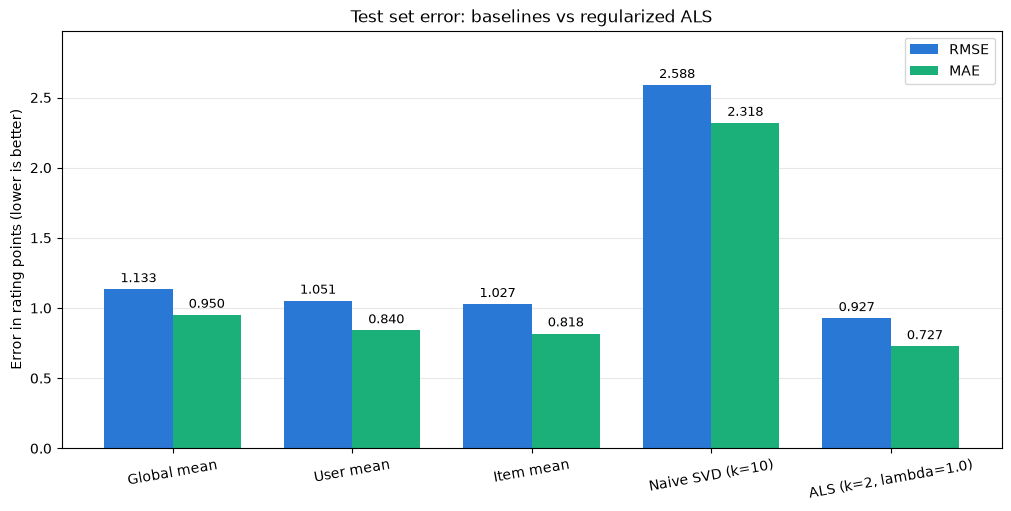

In [14]:
RMSE_COLOR, MAE_COLOR = "#2a78d6", "#1baf7a"

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
x = np.arange(len(test_results))
width = 0.38
bars_rmse = ax.bar(x - width / 2, test_results["Test_RMSE"], width, color=RMSE_COLOR, label="RMSE")
bars_mae = ax.bar(x + width / 2, test_results["Test_MAE"], width, color=MAE_COLOR, label="MAE")
for bars in (bars_rmse, bars_mae):
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_xticks(x, test_results["Model"], rotation=10)
ax.set_ylabel("Error in rating points (lower is better)")
ax.set_ylim(0, test_results[["Test_RMSE", "Test_MAE"]].max().max() * 1.15)
ax.set_title("Test set error: baselines vs regularized ALS")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()
fig.savefig(REPORTS_DIR / "step2_test_errors.png", dpi=150)
plt.show()

### Step 2 results

| Model | Val RMSE | Val MAE | Test RMSE | Test MAE |
|---|---:|---:|---:|---:|
| Global mean | 1.1244 | 0.9433 | 1.1331 | 0.9504 |
| User mean | 1.0358 | 0.8290 | 1.0509 | 0.8400 |
| Item mean | 1.0223 | 0.8144 | 1.0273 | 0.8179 |
| Naive SVD (k = 10) | 2.6165 | 2.3469 | 2.5883 | 2.3183 |
| **ALS (k = 2, lambda = 1.0)** | **0.9227** | **0.7224** | **0.9270** | **0.7270** |

- **ALS is the most accurate model on the test set.** Its test RMSE of 0.9270 is 9.8% lower than the best mean baseline (item mean, 1.0273). On average its predictions are off by about 0.73 stars, against 0.82 for the item mean.
- **Validation and test agree.** Every model ranks in the same order on both sets, and the test error is close to the validation error (+0.004 RMSE for ALS, +0.005 to +0.015 for the mean baselines, -0.03 for naive SVD). So the model choice did not overfit the validation set, and the numbers above are a fair estimate of performance on new ratings from known users and movies.
- **Naive SVD is the worst model, worse even than the global mean.** By Eckart-Young, truncated SVD gives the best rank-k approximation of the zero-filled matrix $R_0$, so it has the lowest possible reconstruction error *on that matrix*. But about 95% of the entries of $R_0$ are artificial zeros, so the model mostly learns to predict "no rating". Its average test prediction is about 1.2 stars, against an average true rating of 3.5. ALS uses the same kind of low-rank model $U V^\top$ but fits only the observed set $\Omega$, with regularization. That difference in the objective, not the rank, is what makes it work.
- **Link to the guiding question.** Two results already show that fitting the data better does not by itself mean predicting better. Naive SVD is optimal for reconstructing its input matrix and fails on held-out ratings. In Step 1, larger k always lowered the training error while raising the validation error. Step 3 asks the next question: whether the model with the lowest rating error also gives the best top-N recommendations.
- The test set has now been used once. From here on, test ratings are used only as ground truth for evaluation (relevance in Step 3, error buckets in Step 6), never to choose or tune a model.

## Step 3. Top-N ranking (M5)

**Goal.** A recommender is not used to predict a star value. It is used to show each user a short list of movies. Here we test whether the model with the lowest rating error (ALS) also produces the best top-N lists, which is the core of the guiding question.

**Method.**
- **Score matrix.** $S = U V^\top \in \mathbb{R}^{943 \times 1682}$ gives a predicted rating for every user-movie pair. Row $i$ is $S_{i,:} = V u_i$: each movie vector $v_j$ is projected onto the user vector $u_i$. Multiplying $u_i$ by a positive constant changes the predicted ratings but not their order. So for ranking, only the *direction* of $u_i$ matters, and the norm of $u_i$ only matters for RMSE.
- **Candidates.** For each user we rank all movies they have not rated in train or validation. Validation movies are also excluded because the user has already watched them (and their ratings were used for model selection). Leaving them in would count a movie the user already rated as a wrong recommendation.
- **Relevance.** A movie is relevant for a user if it appears in the user's test ratings with a rating of at least 4. Users with no relevant test movie cannot be evaluated and are skipped.
- **Metrics** for a list of length $N$ (binary relevance), averaged over users:
  - Precision@N = (relevant movies in the list) / N
  - Recall@N = (relevant movies in the list) / (number of relevant test movies of the user)
  - NDCG@N = DCG / IDCG, with $\text{DCG} = \sum_{r=1}^{N} \text{rel}_r / \log_2(r+1)$. A hit at the top counts more than a hit at the bottom. IDCG is the DCG of the ideal list, so NDCG is between 0 and 1.
- **Models compared:** ALS ($S = U V^\top$), most popular (number of train ratings, same list for everyone), item-mean ranking (highest average train rating, same list for everyone), random (seed 42).
- **Link to the guiding question.** We also rank the 36 ALS models of the Step 1 grid on *validation* by RMSE and by NDCG@10, and check whether the two orders agree. This uses validation only, so the test set stays a one-time evaluation.

In [15]:
from scipy.stats import spearmanr
from task3 import top_n_items, ranking_metrics

N_LIST = [5, 10, 20]

# Dense boolean masks (943 x 1682 is small enough)
train_mask = R_train_coo.toarray() > 0
val_mask = R_val_coo.toarray() > 0
exclude_mask = train_mask | val_mask              # movies the user has already rated

test_dense = R_test_coo.toarray()
relevant_test = test_dense >= 4                    # ground truth: test ratings of 4 or 5
eval_users = np.flatnonzero(relevant_test.sum(axis=1) > 0)

n_skipped = n_users - len(eval_users)
print(f"Users with at least one relevant test movie: {len(eval_users)} / {n_users} (skipped: {n_skipped})")
print(f"Relevant test movies per evaluated user: mean {relevant_test[eval_users].sum(axis=1).mean():.2f}, "
      f"median {np.median(relevant_test[eval_users].sum(axis=1)):.0f}")
print(f"Candidate movies per user: mean {(~exclude_mask).sum(axis=1).mean():.0f}")

# Relevant test movies are never excluded, because the splits are disjoint
assert not (relevant_test & exclude_mask).any()

Users with at least one relevant test movie: 869 / 943 (skipped: 74)
Relevant test movies per evaluated user: mean 6.34, median 4
Candidate movies per user: mean 1587


In [16]:
# Scores for every model: higher = recommended first
popularity = np.bincount(R_train_coo.col, minlength=n_movies)       # number of train ratings per movie
item_mean = movie_avg.loc[unique_movies].to_numpy()                  # train mean rating per movie (Step 2)
rng = np.random.default_rng(RANDOM_STATE)

model_scores = {
    "ALS": U_final @ V_final.T,
    "Most popular": np.tile(popularity, (n_users, 1)).astype(float),
    "Item mean": np.tile(item_mean, (n_users, 1)),
    "Random": rng.random((n_users, n_movies)),
}

# Self-check of the metric code: an oracle that scores exactly the relevant movies must get NDCG = 1
n_rel = relevant_test[eval_users].sum(axis=1)
oracle = ranking_metrics(top_n_items(relevant_test.astype(float), exclude_mask, 10), relevant_test, eval_users)
assert np.isclose(oracle["NDCG"], 1.0)
assert np.isclose(oracle["Precision"], np.mean(np.minimum(n_rel, 10) / 10))
assert np.isclose(oracle["Recall"], np.mean(np.minimum(n_rel, 10) / n_rel))

rows = []
top_lists = {}
for model, scores in model_scores.items():
    top_lists[model] = top_n_items(scores, exclude_mask, max(N_LIST))   # longest list, shorter ones are prefixes
    for n in N_LIST:
        metrics = ranking_metrics(top_lists[model][:, :n], relevant_test, eval_users)
        rows.append({"Model": model, "N": n, **metrics})

topn_results = pd.DataFrame(rows)
topn_results.to_csv(OUTPUT_DIR / "eval_topn_results.csv", index=False)
print(f"Oracle upper bound at N=10: Precision {oracle['Precision']:.4f}, Recall {oracle['Recall']:.4f}")
topn_results.pivot(index="Model", columns="N", values=["Precision", "Recall", "NDCG"]).loc[list(model_scores)].round(4)

Oracle upper bound at N=10: Precision 0.5135, Recall 0.9366


Precision                  Recall                    NDCG  \
N                   5       10      20      5       10      20      5    
Model                                                                    
ALS             0.0384  0.0374  0.0310  0.0245  0.0505  0.0864  0.0399   
Most popular    0.0845  0.0770  0.0610  0.0801  0.1389  0.2035  0.1038   
Item mean       0.0002  0.0003  0.0042  0.0001  0.0007  0.0108  0.0002   
Random          0.0030  0.0035  0.0034  0.0031  0.0052  0.0097  0.0043   

                              
N                 10      20  
Model                         
ALS           0.0473  0.0587  
Most popular  0.1200  0.1408  
Item mean     0.0005  0.0049  
Random        0.0051  0.0067

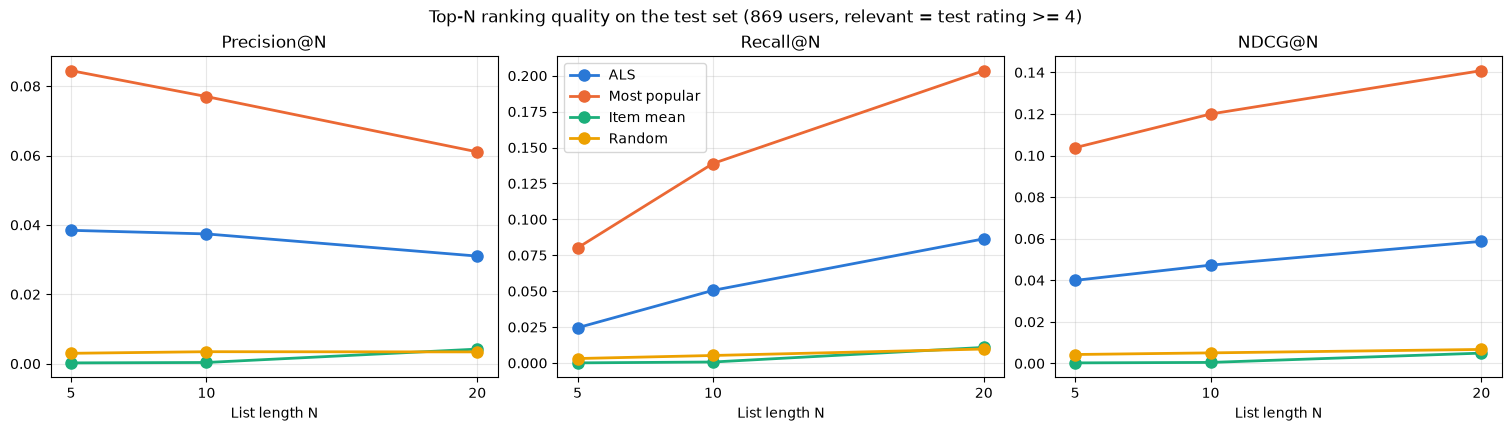

In [17]:
# One panel per metric, N on the x axis, one line per model (fixed colors)
MODEL_COLORS = {"ALS": "#2a78d6", "Most popular": "#eb6834", "Item mean": "#1baf7a", "Random": "#eda100"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for ax, metric in zip(axes, ["Precision", "Recall", "NDCG"]):
    for model, color in MODEL_COLORS.items():
        sub = topn_results[topn_results["Model"] == model]
        ax.plot(sub["N"], sub[metric], color=color, linewidth=2, marker="o", markersize=8, label=model)
    ax.set_xticks(N_LIST)
    ax.set_xlabel("List length N")
    ax.set_title(f"{metric}@N")
    ax.grid(alpha=0.3)
axes[1].legend(loc="upper left")
fig.suptitle(f"Top-N ranking quality on the test set ({len(eval_users)} users, relevant = test rating >= 4)")
fig.savefig(REPORTS_DIR / "step3_topn_metrics.png", dpi=150)
plt.show()

In [18]:
# Why the item-mean ranking fails: its top movies have very few ratings
titles = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ml-100k" / "u.item", sep="|", header=None,
                     encoding="latin-1", usecols=[0, 1], names=["movie_id", "title"]).set_index("movie_id")["title"]

def describe_list(item_indices):
    ids = unique_movies[item_indices]
    return pd.DataFrame({"title": titles.loc[ids].to_numpy(),
                         "train_ratings": popularity[item_indices],
                         "train_mean": item_mean[item_indices].round(2)})

# Global order (before removing the movies each user has already rated)
print("Top 10 by item mean:")
display(describe_list(np.argsort(-item_mean, kind="stable")[:10]))
print(f"Movies with a perfect 5.0 train mean: {(item_mean == 5).sum()}, "
      f"their number of train ratings: max {popularity[item_mean == 5].max()}")
print(f"Median number of train ratings per movie: {np.median(popularity):.0f}")
print("Top 10 by popularity:")
display(describe_list(np.argsort(-popularity, kind="stable")[:10]))

Top 10 by item mean:


,title,train_ratings,train_mean
0,"Great Day in Harlem, A (1994)",1,5.0
1,Grateful Dead (1995),1,5.0
2,They Made Me a Criminal (1939),1,5.0
3,Prefontaine (1997),2,5.0
4,Marlene Dietrich: Shadow and Light (1996),1,5.0
5,Star Kid (1997),2,5.0
6,"Saint of Fort Washington, The (1993)",2,5.0
7,Santa with Muscles (1996),1,5.0
8,Aiqing wansui (1994),1,5.0
9,Someone Else's America (1995),1,5.0


Movies with a perfect 5.0 train mean: 11, their number of train ratings: max 2
Median number of train ratings per movie: 21
Top 10 by popularity:


,title,train_ratings,train_mean
0,Star Wars (1977),471,4.37
1,Return of the Jedi (1983),423,4.01
2,Contact (1997),409,3.80
3,Fargo (1996),405,4.17
4,Liar Liar (1997),394,3.20
5,"English Patient, The (1996)",388,3.64
6,Scream (1996),368,3.41
7,Toy Story (1995),365,3.87
8,Independence Day (ID4) (1996),349,3.44
9,Air Force One (1997),343,3.65


Spearman correlation between Val RMSE and Val NDCG@10 over 36 models: -0.275 (p = 0.1)
Most popular on validation: NDCG@10 = 0.1168
Best by RMSE: k=2, lambda=1.0 -> RMSE 0.9227, NDCG@10 0.0475
Best by NDCG: k=20, lambda=15.0 -> RMSE 0.9917, NDCG@10 0.1361


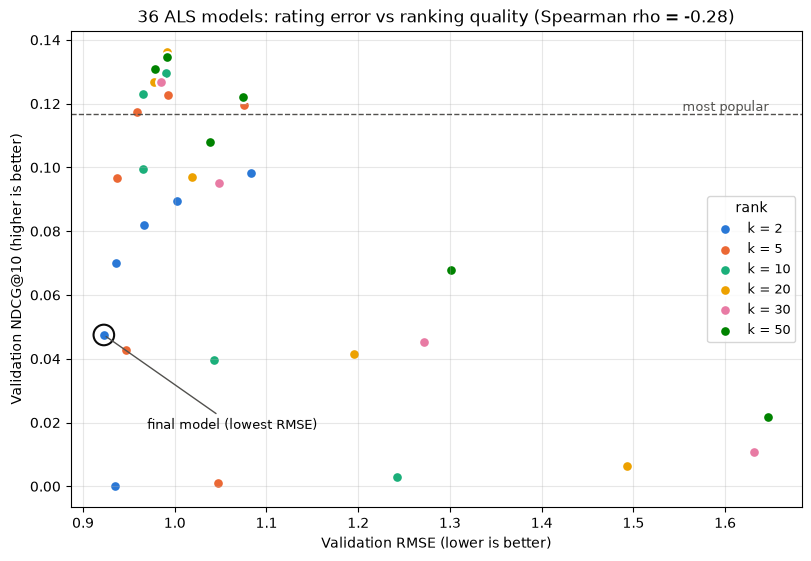

,k,lambda,Val_RMSE,Converged,Val_NDCG@10
13,20,15.0,0.9917,True,0.1361
14,50,15.0,0.9919,True,0.1348
16,30,15.0,0.9929,True,0.1343
10,50,10.0,0.9787,True,0.1307
12,10,15.0,0.9900,True,0.1296
9,20,10.0,0.9774,True,0.1268
11,30,10.0,0.9851,True,0.1267
6,10,10.0,0.9652,True,0.1230


In [19]:
# Guiding question: does a lower RMSE give a better ranking? Compare the 36 ALS models of the Step 1 grid.
# Validation only: relevant = validation rating >= 4, exclude only train movies.
relevant_val = R_val_coo.toarray() >= 4
val_users = np.flatnonzero(relevant_val.sum(axis=1) > 0)

grid_rank = tuning_50[["k", "lambda", "Val_RMSE", "Converged"]].copy()
grid_rank["Val_NDCG@10"] = [
    ranking_metrics(top_n_items(factors[(k, lam)][0] @ factors[(k, lam)][1].T, train_mask, 10), relevant_val, val_users)["NDCG"]
    for k, lam in zip(grid_rank["k"], grid_rank["lambda"])
]
popular_val_ndcg = ranking_metrics(top_n_items(model_scores["Most popular"], train_mask, 10), relevant_val, val_users)["NDCG"]

rho, p_value = spearmanr(grid_rank["Val_RMSE"], grid_rank["Val_NDCG@10"])
print(f"Spearman correlation between Val RMSE and Val NDCG@10 over 36 models: {rho:.3f} (p = {p_value:.2g})")
print(f"Most popular on validation: NDCG@10 = {popular_val_ndcg:.4f}")
best_rmse = grid_rank.loc[grid_rank["Val_RMSE"].idxmin()]
best_ndcg = grid_rank.loc[grid_rank["Val_NDCG@10"].idxmax()]
print(f"Best by RMSE: k={best_rmse['k']:.0f}, lambda={best_rmse['lambda']} -> RMSE {best_rmse['Val_RMSE']:.4f}, NDCG@10 {best_rmse['Val_NDCG@10']:.4f}")
print(f"Best by NDCG: k={best_ndcg['k']:.0f}, lambda={best_ndcg['lambda']} -> RMSE {best_ndcg['Val_RMSE']:.4f}, NDCG@10 {best_ndcg['Val_NDCG@10']:.4f}")

K_COLORS = dict(zip(K_GRID, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
for k, color in K_COLORS.items():
    sub = grid_rank[grid_rank["k"] == k]
    ax.scatter(sub["Val_RMSE"], sub["Val_NDCG@10"], color=color, s=60, edgecolor="white", linewidth=1.5, label=f"k = {k}")
ax.scatter(best_rmse["Val_RMSE"], best_rmse["Val_NDCG@10"], s=220, facecolor="none", edgecolor="#0b0b0b", linewidth=1.5)
ax.annotate("final model (lowest RMSE)", (best_rmse["Val_RMSE"], best_rmse["Val_NDCG@10"]),
            xytext=(0.97, 0.018), textcoords="data", fontsize=9,
            arrowprops=dict(arrowstyle="-", color="#52514e", linewidth=1))
ax.axhline(popular_val_ndcg, color="#52514e", linestyle="--", linewidth=1)
ax.text(grid_rank["Val_RMSE"].max(), popular_val_ndcg, "most popular", ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xlabel("Validation RMSE (lower is better)")
ax.set_ylabel("Validation NDCG@10 (higher is better)")
ax.set_title(f"36 ALS models: rating error vs ranking quality (Spearman rho = {rho:.2f})")
ax.grid(alpha=0.3)
ax.legend(title="rank", fontsize=9)
fig.savefig(REPORTS_DIR / "step3_rmse_vs_ndcg.png", dpi=150)
plt.show()

grid_rank.sort_values("Val_NDCG@10", ascending=False).head(8).round(4)

In [20]:
# Test-set comparison: rating error (Step 2) next to ranking quality (this step)
summary = topn_results[topn_results["N"] == 10].set_index("Model")[["Precision", "Recall", "NDCG"]].add_suffix("@10")
summary.insert(0, "Test_RMSE", [test_rmse_als, np.nan, test_results.loc[2, "Test_RMSE"], np.nan])  # no rating prediction for popular/random
summary.round(4)

,Test_RMSE,Precision@10,Recall@10,NDCG@10
Model,,,,
ALS,0.9270,0.0374,0.0505,0.0473
Most popular,NaN,0.0770,0.1389,0.1200
Item mean,1.0273,0.0003,0.0007,0.0005
Random,NaN,0.0035,0.0052,0.0051


### Step 3 results

**Setup.** 869 of 943 users have at least one test movie rated 4 or 5 and are evaluated. 74 users are skipped. An evaluated user has on average 6.3 relevant test movies (median 4) hidden among about 1,587 candidates, so the task is hard: even a perfect ranker gets Precision@10 of only 0.51, because most users have fewer than 10 relevant movies.

| Model (test, N = 10) | RMSE | Precision@10 | Recall@10 | NDCG@10 |
|---|---:|---:|---:|---:|
| ALS (k = 2, lambda = 1.0) | 0.9270 | 0.0374 | 0.0505 | 0.0473 |
| Most popular | n/a | **0.0770** | **0.1389** | **0.1200** |
| Item mean | 1.0273 | 0.0003 | 0.0007 | 0.0005 |
| Random | n/a | 0.0035 | 0.0052 | 0.0051 |

- **The most accurate rating model is not the best recommender.** ALS ranks about 9 times better than random, but the most-popular list, which ignores the user entirely, is 2 to 3 times better than ALS on every metric and for every N in {5, 10, 20}.
- **Item-mean ranking is worse than random.** Its top 10 are all movies with a perfect 5.0 mean computed from only 1 or 2 ratings (11 movies have a 5.0 mean, none with more than 2 ratings, while the median movie has 21). The mean of $n$ ratings has variance $\sigma^2 / n$, so with $n = 1$ the extreme values come from noise, not quality. These obscure movies almost never appear in anyone's test set. Item mean still has a reasonable RMSE (1.0273, better than the global mean), so it is a second example of good RMSE and useless ranking. A shrunk mean or a minimum number of ratings would fix it.
- **Across the 36 ALS models, RMSE barely predicts ranking quality.** On validation, the Spearman correlation between RMSE and NDCG@10 is only -0.28 (p = 0.1, not significant). The model with the lowest RMSE (k = 2, lambda = 1.0) has NDCG@10 of 0.047. The model with the best NDCG@10 (k = 20, lambda = 15, NDCG 0.136) has a 7.5% worse RMSE (0.992) and is the only kind of ALS model that beats most popular (0.117). k = 2, lambda = 0.1 has the second-best RMSE (0.934) and an NDCG of almost 0. All models above the most-popular line have k >= 5 and strong regularization (lambda >= 10).
- **Why the two criteria disagree.** RMSE is computed only on observed ratings, which users chose to give, mostly to movies they expected to like. Ranking is computed over all unseen movies, most of which the model has never seen any data about. The ALS objective says nothing about how unobserved movies should compare with each other. Strong regularization seems to help ranking, possibly because it shrinks the vectors of rarely rated movies toward zero so they cannot reach the top. We check this in Step 5.
- **Caveat on the evaluation itself.** A movie can only be relevant if the user rated it in the test set, and popular movies are rated much more often. Offline top-N metrics therefore favour popular items, and part of the most-popular advantage comes from the protocol, not from better recommendations. Step 5 quantifies this popularity bias.

**Answer so far to the guiding question:** no. On this data, lower reconstruction error on observed ratings did not produce better recommendations. Choosing the model by RMSE gave a ranking worse than a non-personalized popularity list, and choosing it by a ranking metric on validation would select a different model.

## Step 4. Runtime and memory scaling (M5)

**Goal.** Check how the cost of ALS grows with the rank $k$ and with the number of observed ratings $|\Omega|$, and compare the measurements with the theoretical complexity.

**Theory.** One ALS iteration solves one ridge problem per user and one per movie. For a row $i$ with $|\Omega_i|$ ratings:
- forming $A_i = F_{\Omega_i}^\top F_{\Omega_i} + \lambda I_k$ costs $O(|\Omega_i| k^2)$, and $b_i = F_{\Omega_i}^\top r_{\Omega_i}$ costs $O(|\Omega_i| k)$,
- the Cholesky factorization of the $k \times k$ matrix $A_i$ costs $O(k^3)$.

Summing over all rows gives $O(|\Omega| k^2 + (m+n) k^3)$ per iteration, because $\sum_i |\Omega_i| = |\Omega|$ for both the user and the movie step. Memory is $O((m+n)k + |\Omega|)$: the two factor matrices plus the sparse ratings. The dense $943 \times 1682$ matrix is never built.

**Method.**
- **Time per iteration:** median over 3 iterations of the U-step plus the V-step (two calls to `solve_als_subproblem`), measured with `time.perf_counter`.
- **Peak memory:** `tracemalloc` during a real `fit_als` call with one iteration (sparse copies, $U$, $V$ and the RMSE evaluation).
- **Sweep 1:** $k \in \{2, 5, 10, 20, 50\}$ on the full training set. We add $k = 100$ and $200$, because for small $k$ the per-row Python overhead hides the $k^2$ and $k^3$ terms.
- **Sweep 2:** 25%, 50%, 75% and 100% of the training ratings (random rows, seed 42), with $k = 10$. The index mapping is kept fixed, so the matrix is always $943 \times 1682$ and only $|\Omega|$ changes.
- **Cost model:** we fit the measured times with non-negative least squares on the terms of the theory plus a constant cost per row. The coefficients tell us which term dominates for each $k$.

In [21]:
import tracemalloc
from scipy.optimize import nnls
from task3 import solve_als_subproblem

K_SCALING = [2, 5, 10, 20, 50, 100, 200]   # plan: 2 to 50, plus 100 and 200 to see the asymptotic terms
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
K_FRACTION = 10
N_TIMED_ITER = 3

def measure_als(R_coo, k):
    """Median time of one ALS iteration (U-step + V-step) and peak memory of a fit_als call."""
    R_csr = R_coo.tocsr()
    R_T_csr = R_coo.tocsc().T.tocsr()
    V = np.random.default_rng(RANDOM_STATE).normal(0.0, 0.1, size=(R_coo.shape[1], k))  # values do not change the cost
    times = []
    for _ in range(N_TIMED_ITER):
        start = time.perf_counter()
        U = solve_als_subproblem(V, R_csr, 1.0)
        V = solve_als_subproblem(U, R_T_csr, 1.0)
        times.append(time.perf_counter() - start)

    # Measured separately because tracemalloc slows the code down
    tracemalloc.start()
    fit_als(R_coo, k=k, lambda_reg=1.0, max_iter=1, random_state=RANDOM_STATE, verbose=False)
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()

    # Rows without ratings are skipped by solve_als_subproblem, so only non-empty rows cost a solve
    active_rows = np.count_nonzero(np.diff(R_csr.indptr)) + np.count_nonzero(np.diff(R_T_csr.indptr))
    return {"k": k, "nnz": R_coo.nnz, "active_rows": active_rows,
            "time_per_iter_s": float(np.median(times)), "peak_mem_MB": peak / 1e6}

rows = []
for k in K_SCALING:
    rows.append({"sweep": "rank", **measure_als(R_train_coo, k)})
    print(f"k={k:3d}: {rows[-1]['time_per_iter_s']:.3f} s/iter, peak {rows[-1]['peak_mem_MB']:.1f} MB")

for frac in FRACTIONS:
    sub = train.sample(frac=frac, random_state=RANDOM_STATE)
    R_sub = df_to_coo(sub, user_to_idx, movie_to_idx)   # same mapping: shape stays 943 x 1682
    rows.append({"sweep": "fraction", "fraction": frac, **measure_als(R_sub, K_FRACTION)})
    print(f"{frac:.0%} of train (|Omega| = {R_sub.nnz}): {rows[-1]['time_per_iter_s']:.3f} s/iter, peak {rows[-1]['peak_mem_MB']:.1f} MB")

scaling = pd.DataFrame(rows)
scaling.to_csv(OUTPUT_DIR / "eval_scaling.csv", index=False)

k=  2: 0.035 s/iter, peak 4.6 MB


k=  5: 0.036 s/iter, peak 8.5 MB


k= 10: 0.044 s/iter, peak 15.0 MB


k= 20: 0.051 s/iter, peak 28.0 MB


k= 50: 0.086 s/iter, peak 67.1 MB


k=100: 0.172 s/iter, peak 132.2 MB


k=200: 0.442 s/iter, peak 262.3 MB


25% of train (|Omega| = 20008): 0.037 s/iter, peak 4.0 MB


50% of train (|Omega| = 40016): 0.043 s/iter, peak 7.7 MB


75% of train (|Omega| = 60023): 0.043 s/iter, peak 11.3 MB


100% of train (|Omega| = 80031): 0.044 s/iter, peak 15.0 MB


In [22]:
# Fit the cost models with non-negative least squares, minimizing the RELATIVE error
# (rows divided by the measured value), so that fast and slow runs count the same.
k_arr = scaling["k"].to_numpy(float)
nnz_arr = scaling["nnz"].to_numpy(float)
rows_arr = scaling["active_rows"].to_numpy(float)
m_plus_n = n_users + n_movies

def time_features(k, nnz, rows):
    # constant per solved row (Python loop + call overhead), |Omega| k (b_i, indexing), |Omega| k^2 (A_i), rows k^3 (Cholesky)
    k, nnz, rows = np.broadcast_arrays(np.asarray(k, float), nnz, rows)
    return np.column_stack([rows, nnz * k, nnz * k**2, rows * k**3])

def memory_features(k, nnz):
    # |Omega| (sparse copies), (m+n) k (U, V and their updates), |Omega| k (RMSE evaluation: U[row] and V[col])
    k, nnz = np.broadcast_arrays(np.asarray(k, float), nnz)
    return np.column_stack([nnz, m_plus_n * k, nnz * k])

t = scaling["time_per_iter_s"].to_numpy()
mem = scaling["peak_mem_MB"].to_numpy() * 1e6
A_t, A_m = time_features(k_arr, nnz_arr, rows_arr), memory_features(k_arr, nnz_arr)
coef_time, _ = nnls(A_t / t[:, None], np.ones_like(t))
coef_mem, _ = nnls(A_m / mem[:, None], np.ones_like(mem))
scaling["time_model_s"] = A_t @ coef_time
scaling["mem_model_MB"] = A_m @ coef_mem / 1e6

print("Time model (seconds):")
for name, c in zip(["per solved row", "per |Omega| k", "per |Omega| k^2", "per row k^3"], coef_time):
    print(f"  {name:16s} {c:.2e}")
print(f"  max relative error: {np.max(np.abs(scaling['time_model_s'] / t - 1)):.1%}")
print("Memory model (bytes):")
for name, c in zip(["per rating", "per (m+n) k", "per |Omega| k"], coef_mem):
    print(f"  {name:16s} {c:.1f}")
print(f"  max relative error: {np.max(np.abs(scaling['mem_model_MB'] * 1e6 / mem - 1)):.1%}")

# Share of each term in the predicted time, full training set
rank_rows = scaling[scaling["sweep"] == "rank"]
shares = time_features(rank_rows["k"].to_numpy(float), rank_rows["nnz"].to_numpy(float),
                       rank_rows["active_rows"].to_numpy(float)) * coef_time
shares = pd.DataFrame(shares / shares.sum(axis=1, keepdims=True) * 100, index=rank_rows["k"],
                      columns=["row overhead %", "|Omega| k %", "|Omega| k^2 %", "(m+n) k^3 %"])
shares.round(1)

Time model (seconds):
  per solved row   1.38e-05
  per |Omega| k    8.40e-09
  per |Omega| k^2  8.50e-11
  per row k^3      0.00e+00
  max relative error: 11.4%
Memory model (bytes):
  per rating       25.0
  per (m+n) k      11.3
  per |Omega| k    15.9
  max relative error: 0.0%


,row overhead %,|Omega| k %,|Omega| k^2 %,(m+n) k^3 %
k,,,,
2,96.3,3.6,0.1,0.0
5,91.1,8.5,0.4,0.0
10,83.0,15.4,1.6,0.0
20,69.1,25.7,5.2,0.0
50,41.7,38.7,19.6,0.0
100,21.1,39.2,39.7,0.0
200,8.2,30.4,61.5,0.0


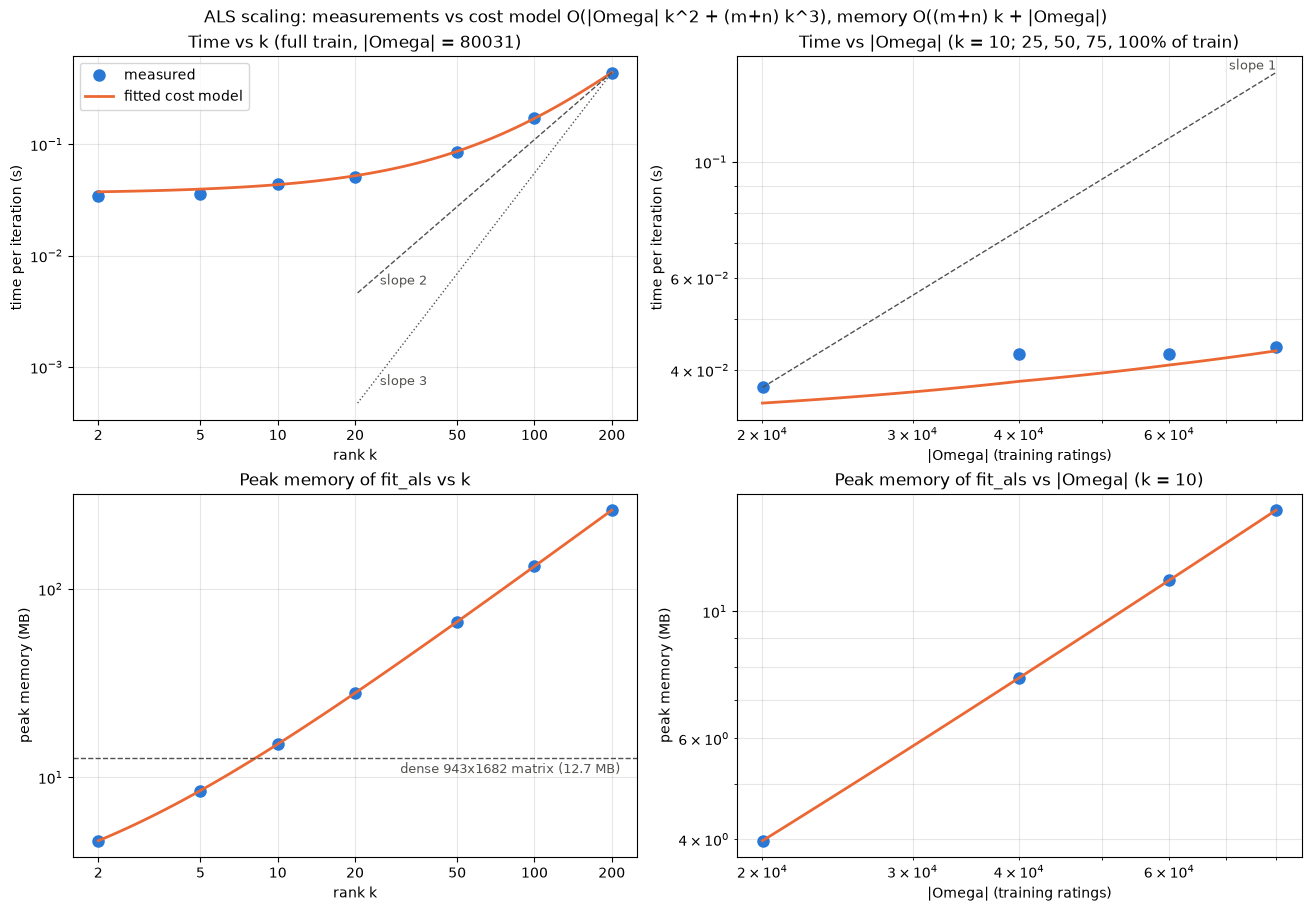

In [23]:
MEASURED_COLOR, MODEL_COLOR, REF_COLOR = "#2a78d6", "#eb6834", "#52514e"
rank_rows = scaling[scaling["sweep"] == "rank"]
frac_rows = scaling[scaling["sweep"] == "fraction"]
k_fine = np.geomspace(2, 200, 100)
nnz_fine = np.linspace(frac_rows["nnz"].min(), frac_rows["nnz"].max(), 100)
full_rows = rank_rows["active_rows"].iloc[0]
# Active rows grow slightly with the fraction: interpolate them for the model line
rows_fine = np.interp(nnz_fine, frac_rows["nnz"], frac_rows["active_rows"])
dense_MB = n_users * n_movies * 8 / 1e6

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

ax = axes[0, 0]
ax.loglog(rank_rows["k"], rank_rows["time_per_iter_s"], "o", color=MEASURED_COLOR, markersize=8, label="measured")
ax.loglog(k_fine, time_features(k_fine, R_train_coo.nnz, full_rows) @ coef_time, color=MODEL_COLOR, linewidth=2, label="fitted cost model")
t_last, k_last = rank_rows["time_per_iter_s"].iloc[-1], rank_rows["k"].iloc[-1]
for power, style in [(2, "--"), (3, ":")]:
    ax.loglog(k_fine[k_fine >= 20], t_last * (k_fine[k_fine >= 20] / k_last) ** power, style, color=REF_COLOR, linewidth=1)
    ax.text(25, t_last * (25 / k_last) ** power, f"slope {power}", color=REF_COLOR, fontsize=9, va="top")
ax.set_xlabel("rank k")
ax.set_ylabel("time per iteration (s)")
ax.set_title(f"Time vs k (full train, |Omega| = {R_train_coo.nnz})")

ax = axes[0, 1]
ax.loglog(frac_rows["nnz"], frac_rows["time_per_iter_s"], "o", color=MEASURED_COLOR, markersize=8, label="measured")
ax.loglog(nnz_fine, time_features(K_FRACTION, nnz_fine, rows_fine) @ coef_time, color=MODEL_COLOR, linewidth=2, label="fitted cost model")
t_first, nnz_first = frac_rows["time_per_iter_s"].iloc[0], frac_rows["nnz"].iloc[0]
ax.loglog(nnz_fine, t_first * nnz_fine / nnz_first, "--", color=REF_COLOR, linewidth=1)
ax.text(nnz_fine[-1], t_first * nnz_fine[-1] / nnz_first, "slope 1", color=REF_COLOR, fontsize=9, ha="right", va="bottom")
ax.set_xlabel("|Omega| (training ratings)")
ax.set_ylabel("time per iteration (s)")
ax.set_title(f"Time vs |Omega| (k = {K_FRACTION}; 25, 50, 75, 100% of train)")

ax = axes[1, 0]
ax.loglog(rank_rows["k"], rank_rows["peak_mem_MB"], "o", color=MEASURED_COLOR, markersize=8, label="measured")
ax.loglog(k_fine, memory_features(k_fine, R_train_coo.nnz) @ coef_mem / 1e6, color=MODEL_COLOR, linewidth=2, label="fitted memory model")
ax.axhline(dense_MB, color=REF_COLOR, linestyle="--", linewidth=1)
ax.text(30, dense_MB * 0.95, f"dense {n_users}x{n_movies} matrix ({dense_MB:.1f} MB)", color=REF_COLOR, fontsize=9, va="top")
ax.set_xlabel("rank k")
ax.set_ylabel("peak memory (MB)")
ax.set_title("Peak memory of fit_als vs k")

ax = axes[1, 1]
ax.loglog(frac_rows["nnz"], frac_rows["peak_mem_MB"], "o", color=MEASURED_COLOR, markersize=8, label="measured")
ax.loglog(nnz_fine, memory_features(K_FRACTION, nnz_fine) @ coef_mem / 1e6, color=MODEL_COLOR, linewidth=2, label="fitted memory model")
ax.set_xlabel("|Omega| (training ratings)")
ax.set_ylabel("peak memory (MB)")
ax.set_title(f"Peak memory of fit_als vs |Omega| (k = {K_FRACTION})")

for ax in axes.flat:
    ax.grid(alpha=0.3, which="both")
for ax in axes[:, 0]:
    ax.set_xticks(K_SCALING, K_SCALING)
    ax.minorticks_off()
axes[0, 0].legend()
fig.suptitle("ALS scaling: measurements vs cost model O(|Omega| k^2 + (m+n) k^3), memory O((m+n) k + |Omega|)")
fig.savefig(REPORTS_DIR / "step4_scaling.png", dpi=150)
plt.show()

### Step 4 results

| k | 2 | 5 | 10 | 20 | 50 | 100 | 200 |
|---|---:|---:|---:|---:|---:|---:|---:|
| time per iteration (s) | 0.035 | 0.036 | 0.044 | 0.051 | 0.086 | 0.172 | 0.442 |
| peak memory (MB) | 4.6 | 8.5 | 15.0 | 28.0 | 67.1 | 132.2 | 262.3 |

Timings are from one laptop, with numpy using a multithreaded BLAS. Times change by a few percent between runs, and the absolute values depend on the machine, but the shape of the curves does not.

**Time vs k.** Multiplying k by 100 (from 2 to 200) multiplies the time only by about 12.6. The log-log curve is almost flat up to k = 20 and reaches a local slope of only about 1.4 between k = 100 and 200, still below the theoretical 2 or 3. The fitted cost model explains why (max relative error about 11%):
- each solved row costs a constant of about 14 microseconds (Python loop, slicing, call to `scipy.linalg.solve`). With 2,625 non-empty rows this alone is about 0.036 s, which is 96% of the time at k = 2.
- the $|\Omega| k$ and $|\Omega| k^2$ terms (building $b_i$ and $A_i = F_{\Omega_i}^\top F_{\Omega_i} + \lambda I$) take over as k grows. At k = 200, $|\Omega| k^2$ is about 60% of the time.
- the fit gives the $(m+n) k^3$ Cholesky term a coefficient of 0. This does not contradict the theory. Each row has on average $2|\Omega| / (m+n) \approx 61$ ratings, so the $k^3/3$ flops of Cholesky only match the $|\Omega_i| k^2$ flops of $A_i$ around $k \approx 180$. LAPACK also runs a Cholesky on a small contiguous matrix much more efficiently than the gather-and-multiply that builds $A_i$. In the tested range the $k^3$ term is too small to measure. It would dominate for $k$ well above 200. Because timings are noisy and the $|\Omega| k^2$ and $(m+n) k^3$ terms grow together over this range, the split between them can change from run to run (in some runs the fit gives the $k^3$ term about 10% of the time at k = 200). The conclusion does not change: row overhead dominates for small k and the $k^2$ work for large k.

**Time vs $|\Omega|$.** With k = 10, using 4 times more ratings increases the time by only 1.2 times, far from the slope 1 line. At k = 10 the cost is dominated by the fixed cost per row, and the number of non-empty rows barely changes (2,378 rows at 25%, 2,625 at 100%). The part of the cost that depends on the data is linear in $|\Omega|$, as the theory says.

**Memory.** tracemalloc is deterministic, and the memory model fits every point exactly. It gives about 25 bytes per rating, 11 bytes per $(m+n)k$ and 16 bytes per $|\Omega| k$:
- 25 bytes per rating are the two CSR copies of $R$ (by user and by movie). Each stores an 8-byte value and a 4-byte column index per rating, so $2 \times 12 = 24$ bytes.
- about 11 bytes per $(m+n)k$ are the factor matrices $U$ and $V$ (8 bytes per entry) plus temporary copies.
- 16 bytes per $|\Omega| k$ are not part of ALS itself. They come from `evaluate_metrics_sparse`, which builds `U[R.row]` and `V[R.col]`, two $|\Omega| \times k$ arrays of 8-byte floats, to compute the training RMSE. At k = 200 this is 256 of the 262 MB. The solver itself only needs about $25|\Omega| + 11(m+n)k \approx 8$ MB, in line with the theoretical $O((m+n)k + |\Omega|)$. Computing the RMSE in chunks of rows would remove this term.

**Sparse vs dense.** On MovieLens 100K the dense $943 \times 1682$ matrix is only 12.7 MB, so sparsity does not matter much here. The advantage grows with the data. For a dataset like MovieLens 25M (about 162,000 users, 62,000 movies, 25 million ratings), a dense float64 matrix would need about 81 GB, while the sparse ratings need about $25 \times 25$ MB, roughly 0.6 GB. ALS never builds the dense matrix, but the naive SVD of Step 2 needs it.

**Practical conclusion.** At this scale ALS is cheap (one fit of 20 to 50 iterations takes 1 to 5 seconds), and its cost is dominated by interpreter overhead, not by linear algebra. Batching the per-row solves (stacking all $A_i$ in one array and calling a vectorized solver) would remove most of the row overhead. The theoretical terms only become visible at large k or with many more ratings per row.

## Step 5. Popularity bias (M6)

**Goal.** Measure how much each recommender concentrates on popular movies, and test the hypothesis from Step 3: strong regularization pushes ALS toward popular movies, which is why it ranks better offline.

**Method.** We use the top-10 lists of Step 3 (movies already rated in train or validation are excluded) for all 943 users. Popularity of a movie = number of train ratings. No test labels are used in this step.
- **Average popularity of recommended movies**, compared with two references: the catalogue average (every movie counts once) and the average popularity of the movies users actually rated in train (every rating counts once, so popular movies weigh more).
- **Head share:** fraction of recommendation slots taken by the 10% most popular movies (168 movies), compared with the share of train ratings these movies receive.
- **Catalogue coverage:** fraction of the 1,682 movies recommended to at least one user.
- **Models:** ALS final (k = 2, lambda = 1, best RMSE), ALS k = 20, lambda = 15 (best validation NDCG@10 in Step 3), most popular, item mean, random.

**Linear algebra behind the hypothesis.** In the V-step, movie $j$ gets $v_j = (U_{\Omega_j}^\top U_{\Omega_j} + \lambda I)^{-1} U_{\Omega_j}^\top r_{\Omega_j}$, where $U_{\Omega_j}$ holds the vectors of the users who rated $j$. When the movie has few ratings, $U_{\Omega_j}^\top U_{\Omega_j}$ is small compared with $\lambda I$ and $v_j \approx U_{\Omega_j}^\top r_{\Omega_j} / \lambda$, a short vector. More ratings make the data term dominate and $v_j$ longer. By Cauchy-Schwarz, the score $u_i^\top v_j \le \|u_i\| \, \|v_j\|$, so short vectors cannot reach the top of a list. We therefore expect $\|v_j\|$ to grow with popularity, and more so for larger lambda.

In [24]:
K_RANK, LAMBDA_RANK = int(best_ndcg["k"]), float(best_ndcg["lambda"])   # best ALS by validation NDCG@10 (Step 3)
U_rank, V_rank = factors[(K_RANK, LAMBDA_RANK)]

TOP_N = 10
rec_lists = {
    f"ALS k={K_FINAL}, lambda={LAMBDA_FINAL:g}": top_lists["ALS"][:, :TOP_N],
    f"ALS k={K_RANK}, lambda={LAMBDA_RANK:g}": top_n_items(U_rank @ V_rank.T, exclude_mask, TOP_N),
    "Most popular": top_lists["Most popular"][:, :TOP_N],
    "Item mean": top_lists["Item mean"][:, :TOP_N],
    "Random": top_lists["Random"][:, :TOP_N],
}

# Head = 10% most popular movies
is_head = np.zeros(n_movies, dtype=bool)
is_head[np.argsort(-popularity, kind="stable")[: n_movies // 10]] = True

catalogue_pop = popularity.mean()                       # each movie counts once
profile_pop = popularity[R_train_coo.col].mean()        # each train rating counts once
head_share_ratings = is_head[R_train_coo.col].mean()
print(f"Catalogue: mean popularity {catalogue_pop:.1f}, median {np.median(popularity):.0f}")
print(f"Movies users rated in train: mean popularity {profile_pop:.1f}")
print(f"The top 10% movies ({is_head.sum()}) receive {head_share_ratings:.1%} of all train ratings")

rows = []
for model, lists in rec_lists.items():
    rec_pop = popularity[lists]
    rows.append({
        "Model": model,
        "Mean_popularity": rec_pop.mean(),
        "Median_popularity": np.median(rec_pop),
        "Head_share": is_head[lists].mean(),
        "Distinct_movies": len(np.unique(lists)),
        "Coverage": len(np.unique(lists)) / n_movies,
    })
popularity_bias = pd.DataFrame(rows)
popularity_bias.to_csv(OUTPUT_DIR / "eval_popularity_bias.csv", index=False)
popularity_bias.round(3)

Catalogue: mean popularity 47.6, median 21
Movies users rated in train: mean popularity 134.5
The top 10% movies (168) receive 42.6% of all train ratings


,Model,Mean_popularity,Median_popularity,Head_share,Distinct_movies,Coverage
0,"ALS k=2, lambda=1",147.436,154.0,0.521,102,0.061
1,"ALS k=20, lambda=15",222.091,216.0,0.799,212,0.126
2,Most popular,347.956,343.0,1.000,69,0.041
3,Item mean,1.299,1.0,0.000,11,0.007
4,Random,41.801,19.0,0.078,1676,0.996


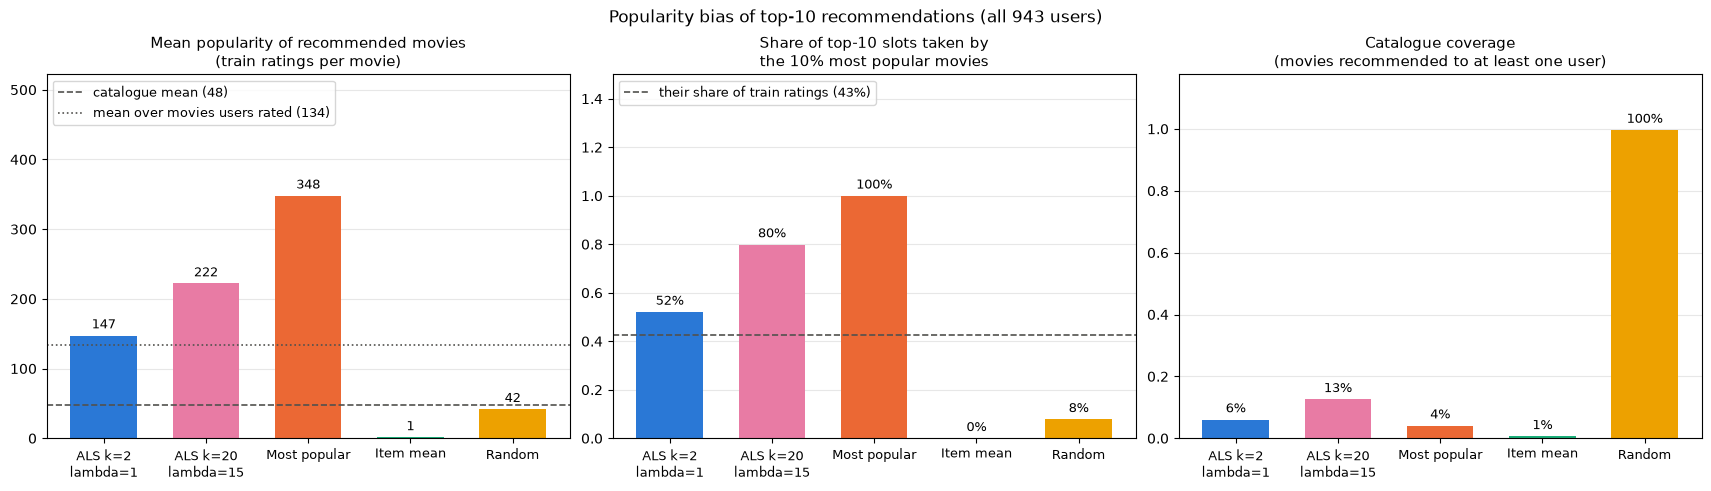

In [25]:
BIAS_COLORS = dict(zip(rec_lists, ["#2a78d6", "#e87ba4", "#eb6834", "#1baf7a", "#eda100"]))
labels = [m.replace(", lambda", "\nlambda") for m in rec_lists]
colors = [BIAS_COLORS[m] for m in rec_lists]
x = np.arange(len(rec_lists))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
panels = [
    ("Mean_popularity", "Mean popularity of recommended movies\n(train ratings per movie)", "{:.0f}",
     [(catalogue_pop, "catalogue mean", "--"), (profile_pop, "mean over movies users rated", ":")]),
    ("Head_share", "Share of top-10 slots taken by\nthe 10% most popular movies", "{:.0%}",
     [(head_share_ratings, "their share of train ratings", "--")]),
    ("Coverage", "Catalogue coverage\n(movies recommended to at least one user)", "{:.0%}", []),
]
for ax, (col, title, fmt, refs) in zip(axes, panels):
    values = popularity_bias[col].to_numpy()
    bars = ax.bar(x, values, color=colors, width=0.65)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=3, fontsize=9)
    for value, text, style in refs:
        ax.axhline(value, color="#52514e", linestyle=style, linewidth=1.2, label=f"{text} ({fmt.format(value)})")
    if refs:
        ax.legend(loc="upper left", fontsize=9)
    ax.set_xticks(x, labels, fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, values.max() * (1.5 if refs else 1.18))
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
fig.suptitle("Popularity bias of top-10 recommendations (all 943 users)")
fig.savefig(REPORTS_DIR / "step5_popularity_bias.png", dpi=150)
plt.show()

Spearman(popularity, ||v_j||): k=2, lambda=1 -> 0.586   k=20, lambda=15 -> 0.949


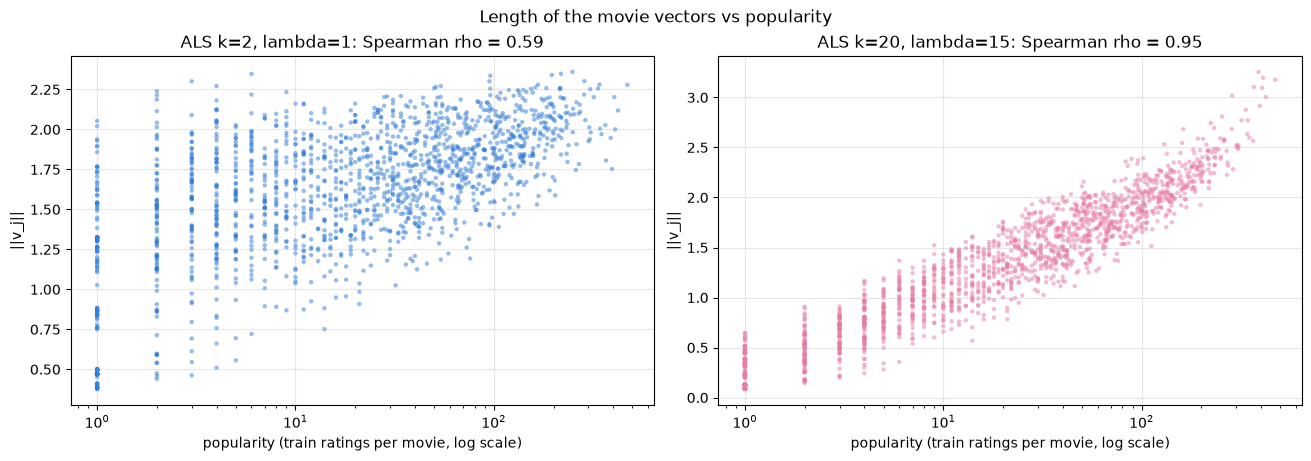

In [26]:
# Hypothesis check: movie vector length vs popularity, for the two ALS models
norm_final = np.linalg.norm(V_final, axis=1)
norm_rank = np.linalg.norm(V_rank, axis=1)
rho_final = spearmanr(popularity, norm_final)[0]
rho_rank = spearmanr(popularity, norm_rank)[0]
print(f"Spearman(popularity, ||v_j||): k={K_FINAL}, lambda={LAMBDA_FINAL:g} -> {rho_final:.3f}   "
      f"k={K_RANK}, lambda={LAMBDA_RANK:g} -> {rho_rank:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, norms, (model, color), rho_m in [
    (axes[0], norm_final, list(BIAS_COLORS.items())[0], rho_final),
    (axes[1], norm_rank, list(BIAS_COLORS.items())[1], rho_rank),
]:
    ax.scatter(popularity, norms, s=10, color=color, alpha=0.5, edgecolor="none")
    ax.set_xscale("log")
    ax.set_xlabel("popularity (train ratings per movie, log scale)")
    ax.set_ylabel("||v_j||")
    ax.set_title(f"ALS {model.replace('ALS ', '')}: Spearman rho = {rho_m:.2f}")
    ax.grid(alpha=0.3)
fig.suptitle("Length of the movie vectors vs popularity")
fig.savefig(REPORTS_DIR / "step5_vector_norm_vs_popularity.png", dpi=150)
plt.show()

### Step 5 results

| Model | Mean popularity | Head share | Distinct movies | Coverage |
|---|---:|---:|---:|---:|
| ALS k = 2, lambda = 1 (best RMSE) | 147 | 52% | 102 | 6.1% |
| ALS k = 20, lambda = 15 (best validation NDCG) | 222 | 80% | 212 | 12.6% |
| Most popular | 348 | 100% | 69 | 4.1% |
| Item mean | 1.3 | 0% | 11 | 0.7% |
| Random | 42 | 8% | 1,676 | 99.6% |

References: the average movie has 47.6 train ratings (median 21). The movies users actually rated have 134.5 on average. The 168 most popular movies (10% of the catalogue) receive 42.6% of all train ratings.

- **Both ALS models amplify popularity.** The 10% most popular movies get 42.6% of the ratings but 52% of the slots in the k = 2 lists and 80% in the k = 20, lambda = 15 lists. Recommendations are more concentrated on popular movies than the users' own behaviour.
- **The hypothesis from Step 3 holds.** The length of the movie vectors follows popularity much more closely with strong regularization: Spearman correlation 0.59 for lambda = 1 and 0.95 for lambda = 15. With lambda = 15 a movie with a single rating gets $\|v_j\| < 0.7$, while the most popular movies reach about 3. Since $u_i^\top v_j \le \|u_i\| \, \|v_j\|$, those movies can never be ranked first. With lambda = 1 some movies with a single rating still get vectors as long as the most popular ones (about 2), which is how a few obscure movies end up in the k = 2 lists. In effect, a large lambda builds a popularity prior into the factorization.
- **The best offline ranker is both more popular and more personalized.** k = 20, lambda = 15 recommends more popular movies than k = 2 (mean 222 vs 147), but it also recommends twice as many different movies (212 vs 102). A rank of 2 gives only two directions to describe all users, so many users receive almost the same list. Rank 20 allows more varied lists, and strong regularization keeps them on well-supported movies. Both effects raise offline NDCG.
- **Coverage is low for every useful model.** ALS recommends at most 13% of the catalogue, and 87% of the movies are never recommended to anyone. Random covers almost everything (its mean popularity of 42 is a bit below the catalogue mean because users have already rated many popular movies, which are excluded) but is useless as a recommender. This is the usual trade-off between accuracy and diversity.
- **Item mean** recommends only 11 different movies, each with about 1 rating. It shows the opposite failure: extreme bias toward the long tail, driven by noise.

**Link to the guiding question.** Step 3 showed that the lowest RMSE does not give the best ranking. This step shows that the model with the best *offline* ranking gets there largely by recommending more popular movies, and offline metrics reward exactly that, because a movie can only be a hit if the user rated it, and popular movies are rated more. So neither RMSE nor offline NDCG alone measures recommendation quality. A complete evaluation should also report popularity and coverage, which tell us how personalized and diverse the lists are.

## Step 6. Cold-start behaviour (M6)

**Goal.** Our split is warm-start: every user and movie in the test set has training ratings. Here we study what happens when a user or movie has *few* ratings, and what happens with none at all.

**Method.**
- **(a) Error by data volume.** We group the test ratings by how many train ratings the user (and, separately, the movie) has, in buckets 1-5, 6-20, 21-50, 51-100, >100. For each bucket we compute the test RMSE of ALS (k = 2, lambda = 1) and of the user-mean and item-mean baselines. The model is fixed, so the test set is only used as ground truth.
- **(b) Simulated cold start.** We choose 100 users at random (seed 42) among those with at least 40 train ratings, and keep only $n \in \{0, 1, 3, 5, 10\}$ of their train ratings (one random order per user, so the profile with $n = 3$ contains the profile with $n = 1$). Everyone else keeps all their ratings. For each $n$ we refit ALS and the baselines on the reduced train and measure the RMSE on the test ratings of these 100 users.
- **Fallback for $n = 0$.** ALS cannot represent a user with no ratings: `solve_als_subproblem` skips empty rows, so $u_i = 0$ and every prediction is $u_i^\top v_j = 0$. For $n = 0$ we therefore use an explicit fallback, either the **global mean** or the **item mean** of the reduced train.

**Linear algebra.** With $n$ ratings, the user vector is $u_i = (V_{\Omega_i}^\top V_{\Omega_i} + \lambda I_k)^{-1} V_{\Omega_i}^\top r_{\Omega_i}$, where $V_{\Omega_i}$ is $n \times k$. If $n < k$, $V_{\Omega_i}^\top V_{\Omega_i}$ has rank at most $n$ and is singular, so least squares without regularization has infinitely many solutions. The $\lambda I$ term makes the system positive definite and selects the shortest solution. The price: with few ratings the data term is small compared with $\lambda I$, and $u_i$ is shrunk toward 0. Our model has no bias terms, so shrinking $u_i$ toward 0 also shrinks the predicted ratings toward 0, not toward the average rating of about 3.5.

In [27]:
BUCKET_EDGES = [0, 5, 20, 50, 100, np.inf]
BUCKET_LABELS = ["1-5", "6-20", "21-50", "51-100", ">100"]
user_train_counts = np.bincount(R_train_coo.row, minlength=n_users)

# One row per test rating: number of train ratings of its user and of its movie, plus every model's prediction
test_rows = pd.DataFrame({
    "rating": R_test_coo.data,
    "user_bucket": pd.cut(user_train_counts[R_test_coo.row], BUCKET_EDGES, labels=BUCKET_LABELS),
    "movie_bucket": pd.cut(popularity[R_test_coo.col], BUCKET_EDGES, labels=BUCKET_LABELS),
    "ALS": np.sum(U_final[R_test_coo.row] * V_final[R_test_coo.col], axis=1),
    "User mean": user_avg.loc[unique_users[R_test_coo.row]].to_numpy(),
    "Item mean": item_mean[R_test_coo.col],
})
BUCKET_MODELS = ["ALS", "User mean", "Item mean"]

def bucket_table(bucket_col):
    out = []
    for label, group in test_rows.groupby(bucket_col, observed=False):
        row = {"bucket": label, "n_test_ratings": len(group)}
        for model in BUCKET_MODELS:
            row[model] = rmse_mae(group[model].to_numpy(), group["rating"].to_numpy())[0] if len(group) else np.nan
        out.append(row)
    return pd.DataFrame(out)

by_user = bucket_table("user_bucket")
by_movie = bucket_table("movie_bucket")
pd.concat([by_user.assign(grouped_by="user"), by_movie.assign(grouped_by="movie")]).to_csv(
    OUTPUT_DIR / "eval_cold_start_buckets.csv", index=False)
print(f"Fewest train ratings of any user: {user_train_counts.min()} (MovieLens 100K keeps only users with >= 20 ratings)")
print("Test RMSE by number of train ratings of the USER:")
display(by_user.round(4))
print("Test RMSE by number of train ratings of the MOVIE:")
display(by_movie.round(4))

Fewest train ratings of any user: 12 (MovieLens 100K keeps only users with >= 20 ratings)
Test RMSE by number of train ratings of the USER:


,bucket,n_test_ratings,ALS,User mean,Item mean
0,1-5,0,NaN,NaN,NaN
1,6-20,394,1.0668,1.1051,1.1700
2,21-50,1290,0.9676,1.0255,1.0298
3,51-100,1784,0.9440,1.0954,1.0312
4,>100,6514,0.9048,1.0400,1.0165


Test RMSE by number of train ratings of the MOVIE:


,bucket,n_test_ratings,ALS,User mean,Item mean
0,1-5,150,1.2261,1.1522,1.3645
1,6-20,524,1.0347,1.1855,1.1351
2,21-50,1444,0.9563,1.1345,1.0779
3,51-100,2285,0.9236,1.0346,1.0299
4,>100,5579,0.9003,1.0182,0.9910


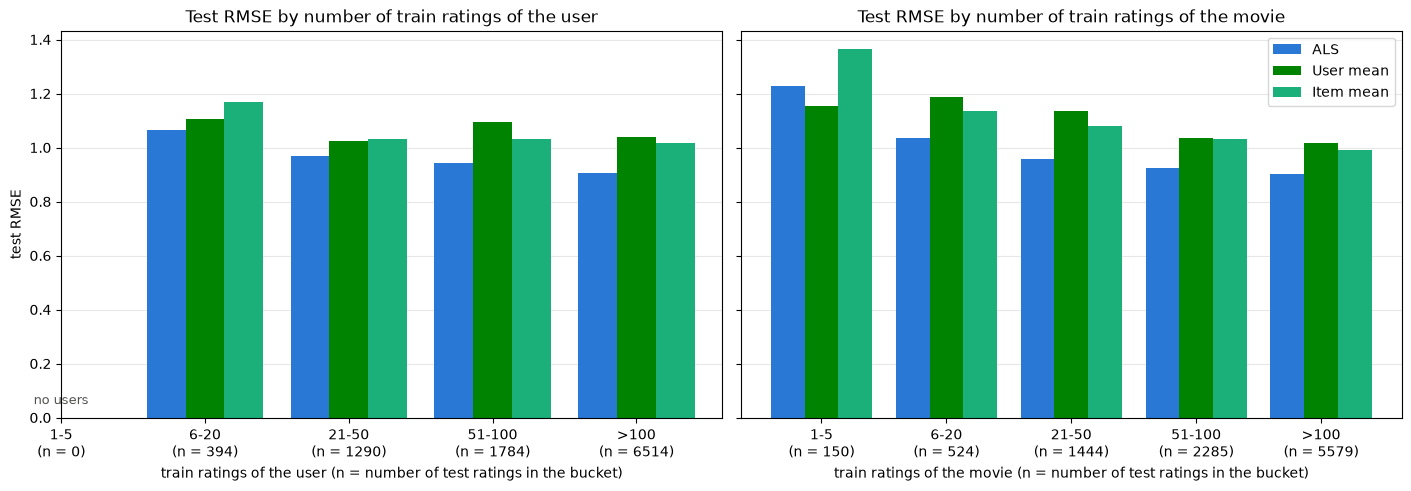

In [28]:
BUCKET_COLORS = {"ALS": "#2a78d6", "User mean": "#008300", "Item mean": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, constrained_layout=True)
width = 0.27
for ax, table, who in [(axes[0], by_user, "user"), (axes[1], by_movie, "movie")]:
    x = np.arange(len(table))
    for i, model in enumerate(BUCKET_MODELS):
        ax.bar(x + (i - 1) * width, table[model], width, color=BUCKET_COLORS[model], label=model)
    ax.set_xticks(x, [f"{b}\n(n = {c})" for b, c in zip(table["bucket"], table["n_test_ratings"])])
    for xi in x[table["n_test_ratings"].to_numpy() == 0]:
        ax.text(xi, 0.05, "no users", ha="center", fontsize=9, color="#52514e")
    ax.set_xlabel(f"train ratings of the {who} (n = number of test ratings in the bucket)")
    ax.set_title(f"Test RMSE by number of train ratings of the {who}")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
axes[0].set_ylabel("test RMSE")
axes[1].legend()
fig.savefig(REPORTS_DIR / "step6_error_by_bucket.png", dpi=150)
plt.show()

In [29]:
# (b) Simulated cold start
COLD_N = [0, 1, 3, 5, 10]
N_COLD_USERS, MIN_TRAIN_RATINGS = 100, 40

users_in_test = np.unique(R_test_coo.row)
candidates = users_in_test[user_train_counts[users_in_test] >= MIN_TRAIN_RATINGS]
cold_users = np.random.default_rng(RANDOM_STATE).choice(candidates, N_COLD_USERS, replace=False)
cold_ids = unique_users[cold_users]
cold_test = test[test["user_id"].isin(cold_ids)]
R_cold_test = df_to_coo(cold_test, user_to_idx, movie_to_idx)
print(f"{N_COLD_USERS} cold users chosen among {len(candidates)} candidates, {len(cold_test)} test ratings")

# Shuffle each cold user's train ratings once, then keep the first n
is_cold = train["user_id"].isin(cold_ids)
cold_train = train[is_cold].sample(frac=1, random_state=RANDOM_STATE)
cold_train["order"] = cold_train.groupby("user_id").cumcount()

sim_rows = []
for n in COLD_N:
    reduced = pd.concat([train[~is_cold], cold_train[cold_train["order"] < n].drop(columns="order")])
    g_avg, u_avg_r, m_avg_r = compute_baseline_averages(reduced)
    base = predict_baseline(cold_test, g_avg, u_avg_r, m_avg_r)
    # A movie rated only by cold users may lose all its train ratings: fall back to the global mean
    n_missing_movies = int(base["movie_avg"].isna().sum())
    base["movie_avg"] = base["movie_avg"].fillna(g_avg)

    row = {"n": n,
           "Global mean": rmse_mae(base["global_avg"].to_numpy(), base["rating"].to_numpy())[0],
           "Item mean": rmse_mae(base["movie_avg"].to_numpy(), base["rating"].to_numpy())[0],
           "User mean": np.nan, "ALS": np.nan, "ALS_mean_prediction": 0.0,
           "test_ratings_without_movie_data": n_missing_movies}
    if n > 0:
        row["User mean"] = rmse_mae(base["user_avg"].to_numpy(), base["rating"].to_numpy())[0]
        # Refit on the reduced train; the index mapping stays fixed, so cold users keep their row
        U_c, V_c, _ = fit_als(df_to_coo(reduced, user_to_idx, movie_to_idx), k=K_FINAL, lambda_reg=LAMBDA_FINAL,
                              max_iter=MAX_ITER, tol=TOL, random_state=RANDOM_STATE, verbose=False)
        als_pred = np.sum(U_c[R_cold_test.row] * V_c[R_cold_test.col], axis=1)
        # Same fallback as the item mean: a movie with no train ratings left has v_j = 0, predict the global mean
        movie_has_data = np.bincount(df_to_coo(reduced, user_to_idx, movie_to_idx).col, minlength=n_movies) > 0
        als_pred = np.where(movie_has_data[R_cold_test.col], als_pred, g_avg)
        row["ALS"] = rmse_mae(als_pred, R_cold_test.data)[0]
        row["ALS_mean_prediction"] = float(als_pred.mean())
    sim_rows.append(row)

cold_sim = pd.DataFrame(sim_rows)
cold_sim.to_csv(OUTPUT_DIR / "eval_cold_start_simulation.csv", index=False)

# Reference: the same users with ALL their train ratings (final model and full-train baselines)
full_ref = {
    "ALS": evaluate_metrics_sparse(R_cold_test, U_final, V_final)[0],
    "Item mean": rmse_mae(cold_test["movie_id"].map(movie_avg).to_numpy(), cold_test["rating"].to_numpy())[0],
    "User mean": rmse_mae(cold_test["user_id"].map(user_avg).to_numpy(), cold_test["rating"].to_numpy())[0],
}
print("With all train ratings: " + ", ".join(f"{m} {v:.4f}" for m, v in full_ref.items()))
print(f"Mean true test rating of these users: {cold_test['rating'].mean():.2f}")
cold_sim.round(4)

100 cold users chosen among 568 candidates, 1440 test ratings


With all train ratings: ALS 0.9085, Item mean 1.1071, User mean 1.0615
Mean true test rating of these users: 3.36


,n,Global mean,Item mean,User mean,ALS,ALS_mean_prediction,test_ratings_without_movie_data
0,0,1.2603,1.1147,NaN,NaN,0.0000,4
1,1,1.2603,1.1147,1.5988,1.5056,2.5400,4
2,3,1.2603,1.1149,1.2612,1.1619,3.0510,4
3,5,1.2603,1.1150,1.2011,1.0724,3.2473,4
4,10,1.2602,1.1146,1.1248,0.9943,3.3334,4


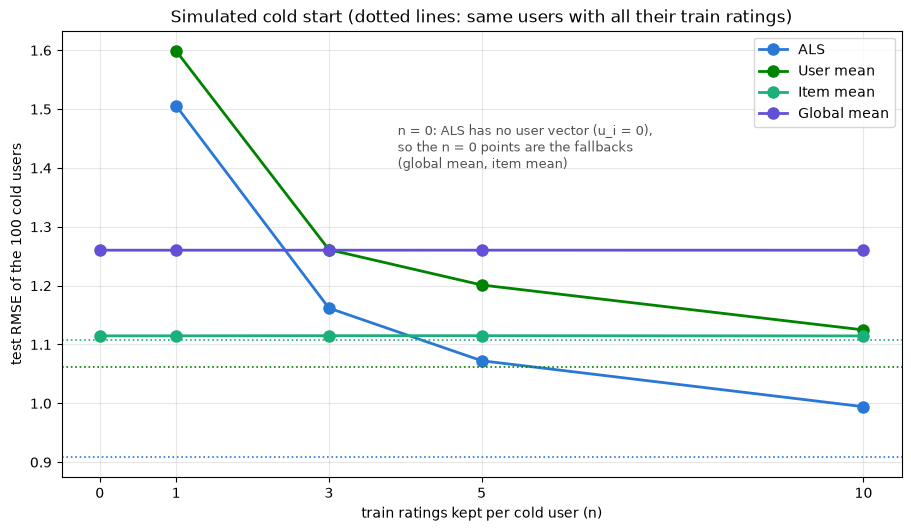

In [30]:
SIM_COLORS = {"ALS": "#2a78d6", "User mean": "#008300", "Item mean": "#1baf7a", "Global mean": "#6250d6"}

fig, ax = plt.subplots(figsize=(9, 5.2), constrained_layout=True)
for model, color in SIM_COLORS.items():
    ax.plot(cold_sim["n"], cold_sim[model], color=color, linewidth=2, marker="o", markersize=8, label=model)
    if model in full_ref:
        ax.axhline(full_ref[model], color=color, linestyle=":", linewidth=1.2)
ax.text(3.9, 1.40, "n = 0: ALS has no user vector (u_i = 0),\nso the n = 0 points are the fallbacks\n(global mean, item mean)",
        fontsize=9, color="#52514e")
ax.set_xticks(COLD_N)
ax.set_xlabel("train ratings kept per cold user (n)")
ax.set_ylabel(f"test RMSE of the {N_COLD_USERS} cold users")
ax.set_title("Simulated cold start (dotted lines: same users with all their train ratings)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(REPORTS_DIR / "step6_simulated_cold_start.png", dpi=150)
plt.show()

### Step 6 results

**(a) Error by data volume (test set, final ALS model).**

| Train ratings | 6-20 | 21-50 | 51-100 | >100 |
|---|---:|---:|---:|---:|
| ALS, grouped by user | 1.067 | 0.968 | 0.944 | 0.905 |
| ALS, grouped by movie | 1.035 | 0.956 | 0.924 | 0.900 |

- No user has 5 or fewer train ratings (the minimum is 12, because MovieLens 100K only keeps users with at least 20 ratings), so the first user bucket is empty. The split really is warm-start for users.
- The error of ALS falls steadily as the user or the movie has more data: from 1.07 to 0.90. Each ridge problem has more equations ($|\Omega_i|$ rows of $F_{\Omega_i}$) for the same $k$ unknowns, so the factor vector is estimated with less variance.
- ALS beats both baselines in every user bucket and in every movie bucket except the rarest one. For movies with 1 to 5 ratings (150 test ratings) ALS has RMSE 1.226, worse than the user mean (1.152), though better than the item mean (1.365). A vector $v_j$ estimated from at most 5 ratings with a small lambda = 1 is noisy, and so is a mean of at most 5 ratings. The user mean ignores the movie entirely and is not affected.

**(b) Simulated cold start (100 users, 1,440 test ratings, mean true rating 3.36).**

| Ratings kept n | 0 | 1 | 3 | 5 | 10 | all |
|---|---:|---:|---:|---:|---:|---:|
| ALS | fallback | 1.506 | 1.162 | 1.072 | 0.994 | 0.909 |
| Item mean | 1.115 | 1.115 | 1.115 | 1.115 | 1.115 | 1.107 |
| User mean | n/a | 1.599 | 1.261 | 1.201 | 1.125 | 1.062 |
| Global mean | 1.260 | 1.260 | 1.260 | 1.260 | 1.260 | |

- **n = 0.** ALS has no information about the user. Its own prediction would be $u_i^\top v_j = 0$, so we must fall back on a baseline: the item mean (RMSE 1.115) is clearly better than the global mean (1.260).
- **n = 1 is worse than no data at all.** With one rating $r$ for movie $j$, the user vector has a closed form. By the Sherman-Morrison formula, $(v_j v_j^\top + \lambda I)^{-1} v_j = v_j / (\lambda + \|v_j\|^2)$, so $u_i = r\, v_j / (\lambda + \|v_j\|^2)$. The user vector points exactly along the one movie seen, and the prediction for any other movie $l$ is $r \, v_j^\top v_l / (\lambda + \|v_j\|^2)$, which depends only on how similar $l$ is to $j$. It is also shrunk toward 0 by the factor $\|v_j\|^2 / (\lambda + \|v_j\|^2)$. The mean ALS prediction is 2.54 against a true mean of 3.36, and the RMSE (1.506) is worse than both fallbacks. The user mean with one rating is even worse (1.599), because a single rating is a very noisy estimate of a user's average.
- **Crossover between 3 and 5 ratings.** ALS needs about 5 ratings to beat the item-mean fallback (1.072 vs 1.115 at n = 5). With 10 ratings it reaches 0.994 and its mean prediction (3.33) is almost unbiased. With all their ratings (at least 40 per user, by construction) it reaches 0.909.
- The item mean barely moves with n because it does not use the user's ratings. Only the means of the movies the cold users rated change slightly. For 4 test ratings, the movie loses all its train ratings, and both the item mean and ALS fall back to the global mean.

**Practical conclusion.** Plain ALS should not be used for users with fewer than about 5 ratings. A simple hybrid is to recommend by item mean (or popularity) until the user has about 5 ratings, then switch to ALS. A better model would add bias terms, $\hat r_{ij} = \mu + b_i + c_j + u_i^\top v_j$. Then regularization would shrink a new user's prediction toward the global mean plus the movie effect, not toward 0, and the small-n case would degrade gracefully into the item-mean baseline.

## Step 7. Latent factor interpretation (M6)

**Goal.** With $k = 2$ every movie is a point $v_j \in \mathbb{R}^2$ and every user a point $u_i \in \mathbb{R}^2$, so we can look at the factors directly and ask what the two dimensions mean.

**Caveat: the axes are not unique.** For any invertible $2 \times 2$ matrix $Q$, $(UQ)(VQ^{-\top})^\top = U Q Q^{-1} V^\top = U V^\top$: the same predictions come from infinitely many factor pairs. The regularization term removes part of this freedom. $\|UQ\|_F^2 + \|VQ^{-\top}\|_F^2$ equals $\|U\|_F^2 + \|V\|_F^2$ for every orthogonal $Q$ (rotations and reflections) but not for a general $Q$. So the regularized objective is unchanged by rotations and reflections only, and ALS lands on one rotation that depends on the random initialization. The raw coordinates $V_{:,0}$ and $V_{:,1}$ therefore have no meaning on their own.

**Method.**
1. Check the caveat numerically: rotate and rescale the factors and compare predictions and penalty.
2. Use **rotation-independent axes**: the direction of the average user $\bar u = \frac{1}{m} \sum_i u_i$ and the direction orthogonal to it. If the factors are rotated by $Q$, $\bar u$ rotates with them, so the coordinates of each movie on these axes do not change. The coordinate along $\bar u$ is proportional to $\bar u^\top v_j$, the rating the average user would give to movie $j$.
3. Look at the movies by genre (from `u.item`), list the movies at both ends of each axis, and correlate the coordinates with popularity and mean rating (Spearman). For the scatter we keep movies with at least 20 train ratings, and for the top/bottom lists at least 50, because vectors estimated from very few ratings are mostly noise (Step 6).

In [31]:
# 1) Non-identifiability check on the final factors
def penalty(U, V):
    return np.sum(U ** 2) + np.sum(V ** 2)

theta = np.pi / 4
Q_rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])   # orthogonal
Q_scale = np.diag([2.0, 0.5])                                                         # invertible, not orthogonal
S_final = U_final @ V_final.T
for name, Q in [("rotation by 45 degrees", Q_rot), ("scaling diag(2, 0.5)", Q_scale)]:
    U_q, V_q = U_final @ Q, V_final @ np.linalg.inv(Q).T
    print(f"{name:24s} max |change in predictions| = {np.abs(U_q @ V_q.T - S_final).max():.1e}, "
          f"penalty {penalty(U_final, V_final):.1f} -> {penalty(U_q, V_q):.1f}")

rotation by 45 degrees   max |change in predictions| = 1.8e-15, penalty 8661.7 -> 8661.7
scaling diag(2, 0.5)     max |change in predictions| = 0.0e+00, penalty 8661.7 -> 18839.9


In [32]:
# 2) Rotation-independent axes: average user direction and its orthogonal complement
u_bar = U_final.mean(axis=0)
d_main = u_bar / np.linalg.norm(u_bar)
d_orth = np.array([-d_main[1], d_main[0]])
coord_main = V_final @ d_main      # proportional to the rating the average user would give
coord_orth = V_final @ d_orth

GENRES = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary", "Drama",
          "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
items = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ml-100k" / "u.item", sep="|", header=None, encoding="latin-1")
items = items.set_index(0).loc[unique_movies]            # same row order as V_final
genre_flags = items.iloc[:, 4:].to_numpy().astype(bool)  # 19 binary genre columns, a movie can have several

# The new coordinates must not change when the factors are rotated
U_r, V_r = U_final @ Q_rot, V_final @ Q_rot
d_r = U_r.mean(axis=0) / np.linalg.norm(U_r.mean(axis=0))
assert np.allclose(V_r @ d_r, coord_main)

factor_corr = pd.DataFrame(
    {name: [spearmanr(values, popularity)[0], spearmanr(values, item_mean)[0]]
     for name, values in [("raw V[:,0]", V_final[:, 0]), ("raw V[:,1]", V_final[:, 1]),
                          ("along average user", coord_main), ("orthogonal", coord_orth),
                          ("length ||v_j||", np.linalg.norm(V_final, axis=1))]},
    index=["Spearman with popularity", "Spearman with mean rating"]).T
factor_corr.round(3)

,Spearman with popularity,Spearman with mean rating
"raw V[:,0]",0.526,0.326
"raw V[:,1]",0.277,0.728
along average user,0.618,0.915
orthogonal,-0.092,0.336
length ||v_j||,0.586,0.918


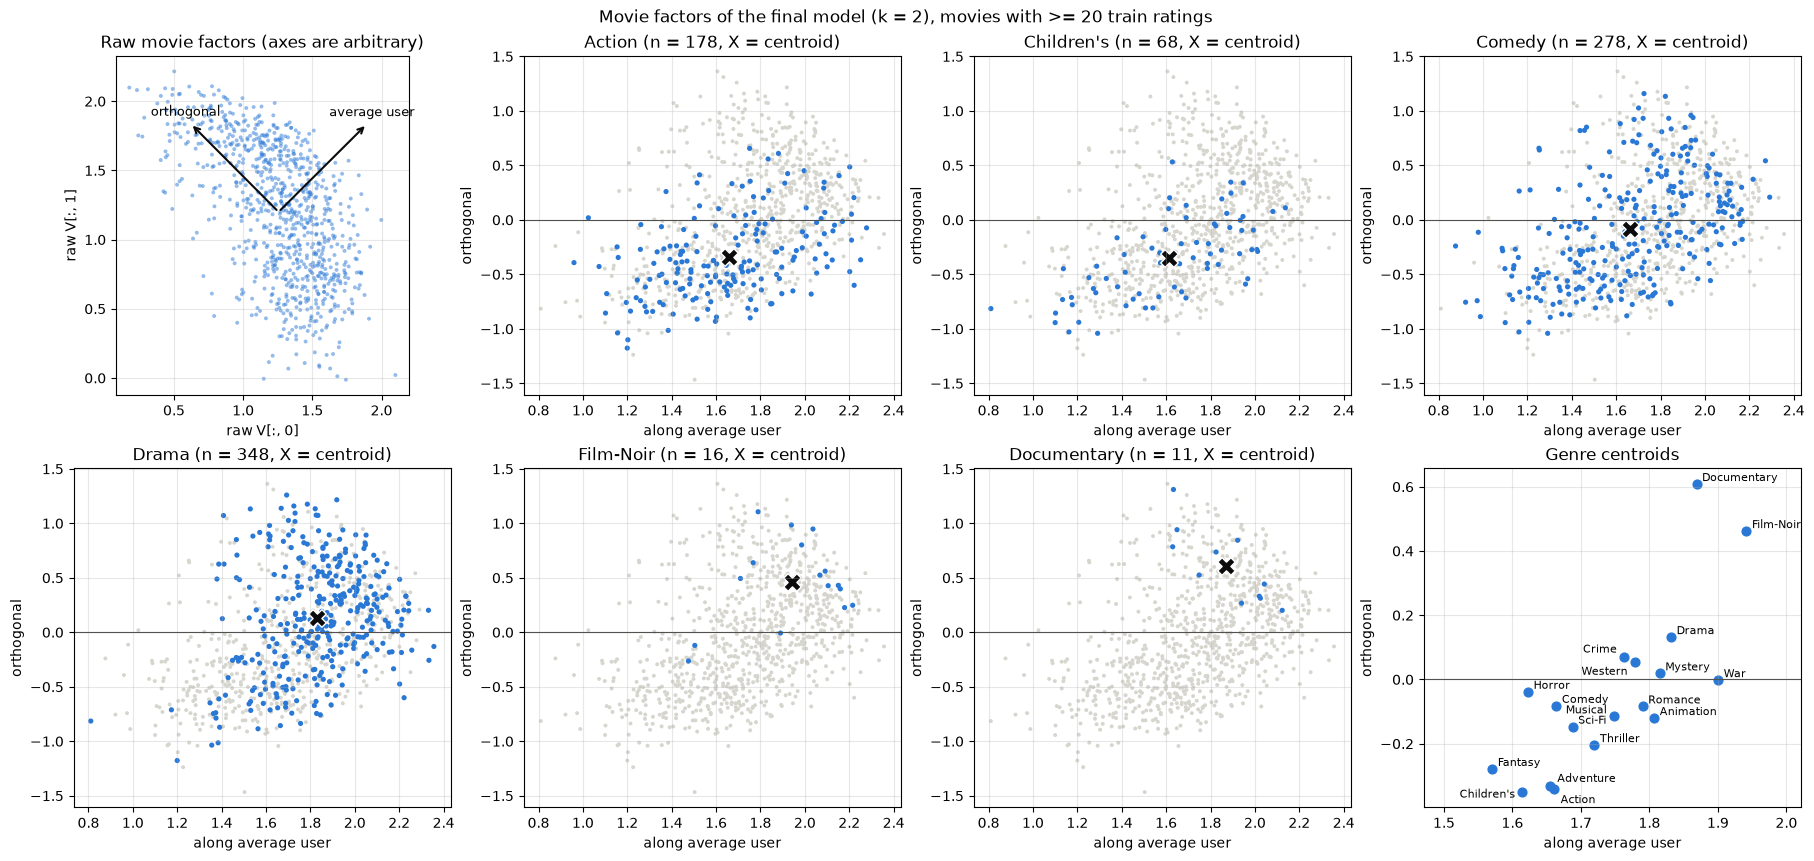

,genre,n_movies,along_average_user,orthogonal
0,Children's,68,1.61,-0.35
1,Action,178,1.66,-0.34
2,Adventure,102,1.66,-0.33
3,Fantasy,13,1.57,-0.28
4,Thriller,174,1.72,-0.20
5,Sci-Fi,82,1.69,-0.15
6,Animation,30,1.81,-0.12
7,Musical,41,1.75,-0.11
8,Romance,153,1.79,-0.08
9,Comedy,278,1.66,-0.08


In [33]:
# Genre centroids on the two axes (movies with >= 20 train ratings)
MIN_RATINGS_PLOT, MIN_RATINGS_LIST = 20, 50
well_rated = popularity >= MIN_RATINGS_PLOT
genre_centroids = pd.DataFrame([
    {"genre": g, "n_movies": int((genre_flags[:, i] & well_rated).sum()),
     "along_average_user": coord_main[genre_flags[:, i] & well_rated].mean(),
     "orthogonal": coord_orth[genre_flags[:, i] & well_rated].mean()}
    for i, g in enumerate(GENRES) if (genre_flags[:, i] & well_rated).any()
]).sort_values("orthogonal").reset_index(drop=True)
genre_centroids.to_csv(OUTPUT_DIR / "eval_latent_genre_centroids.csv", index=False)

HIGHLIGHT_GENRES = ["Action", "Children's", "Comedy", "Drama", "Film-Noir", "Documentary"]
BASE_COLOR, HIGHLIGHT_COLOR = "#d6d5ce", "#2a78d6"

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), constrained_layout=True)
# Panel 1: raw factors with the average-user direction drawn on top
ax = axes[0, 0]
ax.scatter(V_final[well_rated, 0], V_final[well_rated, 1], s=8, color=HIGHLIGHT_COLOR, alpha=0.5, edgecolor="none")
center = V_final[well_rated].mean(axis=0)
for d, text in [(d_main, "average user"), (d_orth, "orthogonal")]:
    ax.annotate("", center + 0.9 * d, center, arrowprops=dict(arrowstyle="->", color="#0b0b0b", linewidth=1.5))
    ax.text(*(center + 0.95 * d), text, fontsize=9, ha="center", va="bottom")
ax.set_xlabel("raw V[:, 0]")
ax.set_ylabel("raw V[:, 1]")
ax.set_title("Raw movie factors (axes are arbitrary)")
ax.set_aspect("equal")

# Panels 2-7: one genre highlighted at a time, in the rotation-independent coordinates
for ax, genre in zip(axes.flat[1:7], HIGHLIGHT_GENRES):
    sel = genre_flags[:, GENRES.index(genre)] & well_rated
    ax.scatter(coord_main[well_rated], coord_orth[well_rated], s=8, color=BASE_COLOR, edgecolor="none")
    ax.scatter(coord_main[sel], coord_orth[sel], s=14, color=HIGHLIGHT_COLOR, edgecolor="none")
    ax.scatter(coord_main[sel].mean(), coord_orth[sel].mean(), s=160, marker="X", color="#0b0b0b", edgecolor="white")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_title(f"{genre} (n = {sel.sum()}, X = centroid)")
    ax.set_xlabel("along average user")
    ax.set_ylabel("orthogonal")

# Panel 8: all genre centroids
ax = axes[1, 3]
ax.scatter(genre_centroids["along_average_user"], genre_centroids["orthogonal"], s=40, color=HIGHLIGHT_COLOR)
# Manual offsets for labels whose points almost coincide
LABEL_OFFSETS = {"Action": (5, -10, "left"), "Adventure": (5, 3, "left"), "Children's": (-5, -4, "right"),
                 "Western": (-5, -9, "right"), "Crime": (-5, 3, "right"), "Musical": (-5, 2, "right")}
for _, row in genre_centroids.iterrows():
    dx, dy, ha = LABEL_OFFSETS.get(row["genre"], (4, 2, "left"))
    ax.annotate(row["genre"], (row["along_average_user"], row["orthogonal"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, ha=ha)
ax.set_xlim(genre_centroids["along_average_user"].min() - 0.1, genre_centroids["along_average_user"].max() + 0.08)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_title("Genre centroids")
ax.set_xlabel("along average user")
ax.set_ylabel("orthogonal")
for ax in axes.flat:
    ax.grid(alpha=0.3)
fig.suptitle(f"Movie factors of the final model (k = 2), movies with >= {MIN_RATINGS_PLOT} train ratings")
fig.savefig(REPORTS_DIR / "step7_latent_factors_genres.png", dpi=150)
plt.show()

genre_centroids.round(2)

In [34]:
# Movies at both ends of each axis (>= 50 train ratings)
def genre_string(j):
    return ", ".join(g for g, flag in zip(GENRES, genre_flags[j]) if flag)

def axis_extremes(coord, n=8):
    order = np.argsort(coord, kind="stable")
    order = order[popularity[order] >= MIN_RATINGS_LIST]
    rows = []
    for end, idx in [("bottom", order[:n]), ("top", order[::-1][:n])]:
        for j in idx:
            rows.append({"end": end, "title": items.iloc[j, 0], "genres": genre_string(j), "coord": round(coord[j], 2),
                         "train_ratings": popularity[j], "mean_rating": round(item_mean[j], 2)})
    return pd.DataFrame(rows)

print("Axis 1, along the average user:")
display(axis_extremes(coord_main))
print("Axis 2, orthogonal:")
display(axis_extremes(coord_orth))

Axis 1, along the average user:


,end,title,genres,coord,train_ratings,mean_rating
0,bottom,McHale's Navy (1997),"Comedy, War",0.97,59,2.05
1,bottom,Striptease (1996),"Comedy, Crime",1.10,54,2.26
2,bottom,Jungle2Jungle (1997),"Children's, Comedy",1.10,98,2.46
3,bottom,"Beautician and the Beast, The (1997)","Comedy, Romance",1.12,75,2.32
4,bottom,"Very Brady Sequel, A (1996)",Comedy,1.16,76,2.28
5,bottom,"Phantom, The (1996)",Adventure,1.23,65,2.52
6,bottom,Sgt. Bilko (1996),Comedy,1.23,61,2.54
7,bottom,"Cable Guy, The (1996)",Comedy,1.25,86,2.40
8,top,Schindler's List (1993),"Drama, War",2.36,249,4.49
9,top,"Shawshank Redemption, The (1994)",Drama,2.33,218,4.46


Axis 2, orthogonal:


,end,title,genres,coord,train_ratings,mean_rating
0,bottom,First Knight (1995),"Action, Adventure, Drama, Romance",-1.01,66,2.89
1,bottom,Jungle2Jungle (1997),"Children's, Comedy",-0.94,98,2.46
2,bottom,Twister (1996),"Action, Adventure, Thriller",-0.93,233,3.21
3,bottom,Dirty Dancing (1987),"Musical, Romance",-0.92,80,3.12
4,bottom,"Jackal, The (1997)","Action, Thriller",-0.91,65,3.18
5,bottom,Independence Day (ID4) (1996),"Action, Sci-Fi, War",-0.90,349,3.44
6,bottom,"Ghost and the Darkness, The (1996)","Action, Adventure",-0.89,102,3.26
7,bottom,Up Close and Personal (1996),"Drama, Romance",-0.89,62,3.26
8,top,Crumb (1994),Documentary,1.31,66,3.82
9,top,Three Colors: Blue (1993),Drama,1.22,54,4.07


### Step 7 results

**Non-identifiability, checked.** Rotating the factors by 45 degrees changes the predictions by at most $1.8 \times 10^{-15}$ (rounding error) and leaves the penalty unchanged (8661.7). Rescaling with $Q = \text{diag}(2, 0.5)$ also leaves the predictions unchanged, but the penalty more than doubles (18839.9), so the regularized objective rules it out. Only rotations and reflections remain free. This is why the raw axes are mixed: $V_{:,0}$ correlates 0.53 with popularity and 0.33 with mean rating, $V_{:,1}$ 0.28 and 0.73. Neither has a clean meaning.

**Axis 1 (direction of the average user) = general appeal.** The coordinate along $\bar u$ has Spearman correlation **0.915 with the mean rating** of the movie (0.62 with popularity). At the bottom are poorly rated comedies (McHale's Navy, Striptease, Jungle2Jungle, mean ratings 2.0 to 2.5). At the top are the classics everyone likes (Schindler's List, Shawshank Redemption, Casablanca, Star Wars, the Wallace and Gromit shorts, mean ratings around 4.4 to 4.5). Since $\bar u^\top v_j$ is the rating the average user would give, this axis plays the same role as the item mean, learned inside the factorization.

**Axis 2 (orthogonal) = mainstream blockbusters vs auteur and art-house cinema.** This coordinate is almost uncorrelated with popularity (-0.09) and only weakly with mean rating (0.34), so it captures *taste*, not quality. At the negative end are 1990s Hollywood action and adventure films (Twister, Independence Day, First Knight, The Jackal, The Ghost and the Darkness). At the positive end are documentaries, European and independent films and cult titles (Crumb, Three Colors: Blue, Big Night, A Clockwork Orange, Lost Highway, Heavenly Creatures, The City of Lost Children). Twister (mean 3.21) and Lost Highway (mean 3.12) have similar ratings but sit at opposite ends. The genre centroids follow the same order: Children's (-0.35), Action (-0.34), Adventure (-0.33) at one end, Drama (+0.13), Film-Noir (+0.46), Documentary (+0.61) at the other.

**Reading a prediction.** Since $d_1 = \bar u / \|\bar u\|$ and $d_2$ form an orthonormal basis, every prediction splits into two terms:
$$\hat r_{ij} = u_i^\top v_j = (u_i^\top d_1)(v_j^\top d_1) + (u_i^\top d_2)(v_j^\top d_2).$$
The first term is "how generous the user is" times "how good the movie is". The second is the taste match: positive when user and movie are on the same side of the mainstream/art-house axis, negative otherwise.

**Limits.**
- Genres separate only on average. Within every genre the spread is large (Comedy and Drama cover almost the whole cloud), because genre labels are coarse and a movie can have several.
- The choice of axes is ours. Any rotation describes the same model, and we chose the one aligned with the average user because it makes the first coordinate directly interpretable. What the model really contains is the geometry (lengths and angles), not the axes.
- Movies with few ratings were left out of the plots. Their vectors are mostly shrinkage and noise (Step 6).

**Link to the guiding question.** Most of what the k = 2 model learns lies along axis 1, the general-appeal direction, which is essentially the item-mean signal. That signal lowers RMSE a lot, but it is the same for every user. All personalization has to fit into the single orthogonal direction. This explains why the k = 2 model has the best RMSE but produces nearly identical lists for many users (102 distinct movies in Step 5) and ranks worse than models with higher rank.

## Step 8. Write-up: does a lower reconstruction error give better recommendations?

**Goal.** Bring the evidence together and answer the guiding question.

**One more test evaluation.** Step 3 showed that selecting ALS by validation NDCG@10 picks a different model (k = 20, lambda = 15) than selecting by validation RMSE (k = 2, lambda = 1). Both choices were made on validation only, so we can evaluate the second model on the test set once, exactly like the first. This gives a clean test-set comparison of the two selection criteria.

In [35]:
# Ranking-selected model (best validation NDCG@10 in Step 3), evaluated on the test set once
np.save(OUTPUT_DIR / "eval_U_rank.npy", U_rank)
np.save(OUTPUT_DIR / "eval_V_rank.npy", V_rank)

val_rmse_rank, val_mae_rank = evaluate_metrics_sparse(R_val_coo, U_rank, V_rank)
test_rmse_rank, test_mae_rank = evaluate_metrics_sparse(R_test_coo, U_rank, V_rank)
top_lists["ALS rank-selected"] = top_n_items(U_rank @ V_rank.T, exclude_mask, max(N_LIST))
rank_topn = pd.DataFrame([{"N": n, **ranking_metrics(top_lists["ALS rank-selected"][:, :n], relevant_test, eval_users)}
                          for n in N_LIST])
print(f"ALS k={K_RANK}, lambda={LAMBDA_RANK:g}: Val RMSE {val_rmse_rank:.4f}, Test RMSE {test_rmse_rank:.4f}, Test MAE {test_mae_rank:.4f}")
rank_topn.round(4)

ALS k=20, lambda=15: Val RMSE 0.9917, Test RMSE 0.9878, Test MAE 0.7768


,N,Precision,Recall,NDCG
0,5,0.0983,0.0926,0.1284
1,10,0.0815,0.1544,0.1395
2,20,0.0662,0.2349,0.1648


In [36]:
# Final comparison on the test set: rating accuracy and ranking quality side by side
def topn_at(model, n=10):
    row = topn_results[(topn_results["Model"] == model) & (topn_results["N"] == n)].iloc[0]
    return row["Precision"], row["Recall"], row["NDCG"]

final_rows = [
    ("Item mean", "baseline", test_results.loc[2, "Val_RMSE"], test_results.loc[2, "Test_RMSE"], test_results.loc[2, "Test_MAE"], *topn_at("Item mean")),
    (f"ALS k={K_FINAL}, lambda={LAMBDA_FINAL:g}", "validation RMSE", val_rmse_als, test_rmse_als, test_mae_als, *topn_at("ALS")),
    (f"ALS k={K_RANK}, lambda={LAMBDA_RANK:g}", "validation NDCG@10", val_rmse_rank, test_rmse_rank, test_mae_rank,
     *rank_topn.loc[rank_topn["N"] == 10, ["Precision", "Recall", "NDCG"]].iloc[0]),
    ("Most popular", "baseline", np.nan, np.nan, np.nan, *topn_at("Most popular")),
    ("Random", "baseline", np.nan, np.nan, np.nan, *topn_at("Random")),
]
final_comparison = pd.DataFrame(final_rows, columns=["Model", "Selected_by", "Val_RMSE", "Test_RMSE", "Test_MAE",
                                                     "Test_Precision@10", "Test_Recall@10", "Test_NDCG@10"])
final_comparison.to_csv(OUTPUT_DIR / "eval_final_comparison.csv", index=False)
final_comparison.round(4)

,Model,Selected_by,Val_RMSE,Test_RMSE,Test_MAE,Test_Precision@10,Test_Recall@10,Test_NDCG@10
0,Item mean,baseline,1.0223,1.0273,0.8179,0.0003,0.0007,0.0005
1,"ALS k=2, lambda=1",validation RMSE,0.9227,0.9270,0.7270,0.0374,0.0505,0.0473
2,"ALS k=20, lambda=15",validation NDCG@10,0.9917,0.9878,0.7768,0.0815,0.1544,0.1395
3,Most popular,baseline,NaN,NaN,NaN,0.0770,0.1389,0.1200
4,Random,baseline,NaN,NaN,NaN,0.0035,0.0052,0.0051


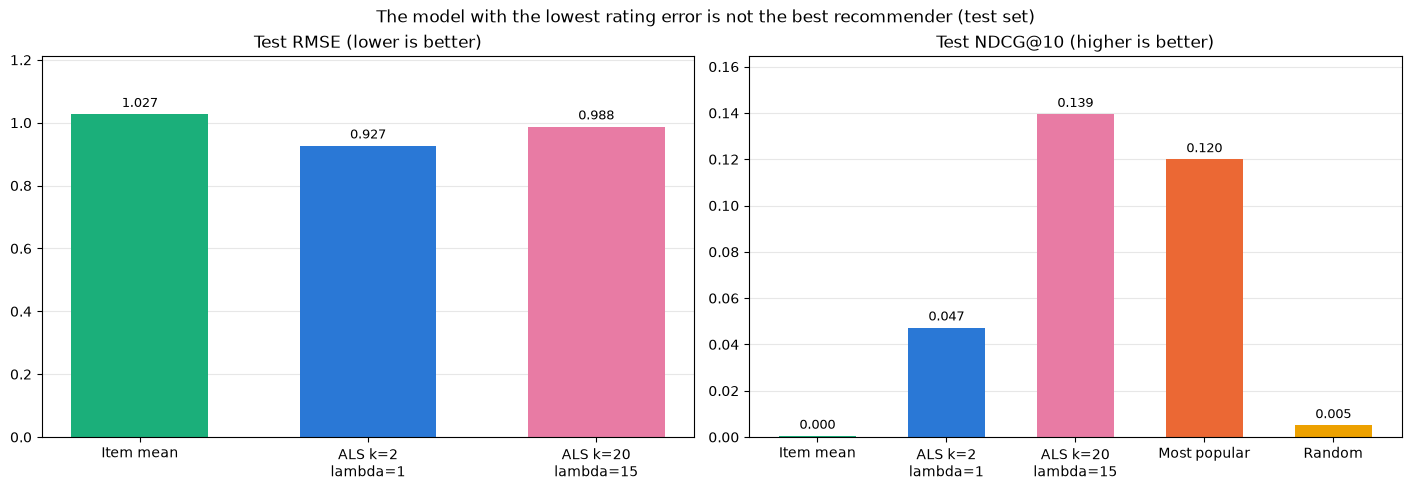

In [37]:
FINAL_COLORS = {"Item mean": "#1baf7a", f"ALS k={K_FINAL}, lambda={LAMBDA_FINAL:g}": "#2a78d6",
                f"ALS k={K_RANK}, lambda={LAMBDA_RANK:g}": "#e87ba4", "Most popular": "#eb6834", "Random": "#eda100"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for ax, col, title in [(axes[0], "Test_RMSE", "Test RMSE (lower is better)"),
                       (axes[1], "Test_NDCG@10", "Test NDCG@10 (higher is better)")]:
    sub = final_comparison.dropna(subset=[col])
    labels = [m.replace(", lambda", "\nlambda") for m in sub["Model"]]
    bars = ax.bar(labels, sub[col], color=[FINAL_COLORS[m] for m in sub["Model"]], width=0.6)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_ylim(0, sub[col].max() * 1.18)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
fig.suptitle("The model with the lowest rating error is not the best recommender (test set)")
fig.savefig(REPORTS_DIR / "step8_rmse_vs_ranking_test.png", dpi=150)
plt.show()

In [38]:
# Are the NDCG@10 gaps real? Paired bootstrap over the 869 evaluated users (2,000 resamples, seed 42)
def per_user_ndcg(top):
    return np.array([ranking_metrics(top[:, :10], relevant_test, np.array([u]))["NDCG"] for u in eval_users])

ndcg_rank_u = per_user_ndcg(top_lists["ALS rank-selected"])
ndcg_pop_u = per_user_ndcg(top_lists["Most popular"])
ndcg_rmse_u = per_user_ndcg(top_lists["ALS"])
assert np.isclose(ndcg_rank_u.mean(), rank_topn.loc[rank_topn["N"] == 10, "NDCG"].iloc[0])   # same numbers as above

boot_idx = np.random.default_rng(RANDOM_STATE).integers(0, len(eval_users), size=(2000, len(eval_users)))
for name, other in [("most popular", ndcg_pop_u), (f"ALS k={K_FINAL}, lambda={LAMBDA_FINAL:g}", ndcg_rmse_u)]:
    diff = ndcg_rank_u - other
    low, high = np.percentile(diff[boot_idx].mean(axis=1), [2.5, 97.5])
    print(f"NDCG@10 of ALS k={K_RANK}, lambda={LAMBDA_RANK:g} minus {name}: {diff.mean():+.4f}, 95% CI [{low:+.4f}, {high:+.4f}]")

NDCG@10 of ALS k=20, lambda=15 minus most popular: +0.0195, 95% CI [+0.0059, +0.0340]
NDCG@10 of ALS k=20, lambda=15 minus ALS k=2, lambda=1: +0.0922, 95% CI [+0.0805, +0.1044]


### Summary and answer to the guiding question

**Does a lower reconstruction error on observed ratings necessarily produce better recommendations for unseen items? No.** On MovieLens 100K, the model chosen for the lowest rating error ranks clearly worse than a model chosen for ranking quality, and even worse than a non-personalized popularity list.

**Main evidence (test set, used once per model; both ALS models were selected on validation only).**

| Model | Selected by | Test RMSE | Test MAE | Precision@10 | Recall@10 | NDCG@10 |
|---|---|---:|---:|---:|---:|---:|
| Item mean | baseline | 1.0273 | 0.8179 | 0.0003 | 0.0007 | 0.0005 |
| ALS k = 2, lambda = 1 | validation RMSE | **0.9270** | **0.7270** | 0.0374 | 0.0505 | 0.0473 |
| ALS k = 20, lambda = 15 | validation NDCG@10 | 0.9878 | 0.7768 | **0.0815** | **0.1544** | **0.1395** |
| Most popular | baseline | n/a | n/a | 0.0770 | 0.1389 | 0.1200 |
| Random | baseline | n/a | n/a | 0.0035 | 0.0052 | 0.0051 |

- Selecting by RMSE gives k = 2, lambda = 1. Selecting by NDCG@10 gives k = 20, lambda = 15, whose RMSE is 6.6% worse but whose NDCG@10 is about 3 times higher (+0.092, 95% bootstrap CI [+0.081, +0.104]). It is also the only model that beats the most-popular list (+0.020, CI [+0.006, +0.034]). Validation and test agree for both models, so these are not selection artefacts.
- The same pattern appears four more times, at different scales:
  1. **Naive SVD** is, by Eckart-Young, the best rank-k approximation of the zero-filled matrix, and it has the worst test RMSE (2.59), worse than predicting the global mean (Step 2).
  2. **Item mean** has a reasonable RMSE (1.027, better than the global mean) and a ranking worse than random, because its top movies have one or two 5-star ratings (Step 3).
  3. **Across the 36 ALS models** of the grid, validation RMSE and validation NDCG@10 are barely related (Spearman -0.28, p = 0.1). k = 2, lambda = 0.1 has the second-best RMSE and an NDCG of almost 0 (Step 3).
  4. **Larger k** always lowers the training error (down to 0.17) but raises the validation error (Step 1).

**Why the two goals diverge (mechanisms we observed).**
1. *Different sets of items.* RMSE is measured on the ratings users chose to give. Ranking is done over about 1,587 unseen movies per user, about which the training objective says nothing.
2. *RMSE rewards a signal that is the same for every user.* With k = 2, the main latent axis is "general appeal" (Spearman 0.915 with the mean rating, Step 7). It lowers RMSE but does not personalize, and the k = 2 model gives near-identical lists (102 distinct movies across 943 users, Step 5).
3. *Strong regularization acts as a popularity prior.* $v_j = (U_{\Omega_j}^\top U_{\Omega_j} + \lambda I)^{-1} U_{\Omega_j}^\top r_{\Omega_j}$ is short for rarely rated movies. With lambda = 15 the vector length follows popularity almost perfectly (Spearman 0.95, vs 0.59 for lambda = 1, Step 5), so obscure movies cannot reach the top. This raises offline ranking metrics, which themselves favour popular items.

**Caveats.**
- The better offline ranker is also more popularity-biased (80% of its slots go to the 10% most popular movies) and covers only 12.6% of the catalogue. Offline NDCG partly rewards popularity, so a live test would be needed to confirm the gain for real users.
- One split, one seed, warm-start users and movies, and a plain ALS model without bias terms. Without biases, ALS needs about 5 ratings to beat the item-mean fallback for a new user (Step 6).
- Computationally, ALS is cheap at this scale (0.03 to 0.4 s per iteration). Its cost is dominated by per-row Python overhead, and memory stays far below what a dense matrix would need at larger scales (Step 4).

**Practical recommendation.** Choose hyperparameters with the metric of the real task: a ranking metric on validation for top-N recommendation, RMSE only if the product shows predicted stars. Always report popularity and coverage next to accuracy, and use a fallback (item mean or popularity) for users with fewer than about 5 ratings.

---

### Figures for the report (8 to 12 pages)

Core figures, in reading order:

| # | File | Message |
|---|---|---|
| 1 | `step1_heatmaps_val_rmse.png` | Grid search after convergence: same winner, overfitting corner |
| 2 | `step1_learning_curves.png` | Train/validation gap grows with k |
| 3 | `step2_test_errors.png` | Test RMSE/MAE: ALS best, naive SVD worst |
| 4 | `step3_rmse_vs_ndcg.png` | 36 models: RMSE barely predicts ranking quality |
| 5 | `step8_rmse_vs_ranking_test.png` | Test set: RMSE-selected vs NDCG-selected model |
| 6 | `step5_vector_norm_vs_popularity.png` | Mechanism: lambda as a popularity prior |
| 7 | `step4_scaling.png` | Runtime and memory vs theory |
| 8 | `step6_simulated_cold_start.png` | Cold start: crossover at about 5 ratings |
| 9 | `step7_latent_factors_genres.png` | Meaning of the two latent axes |

Appendix or optional: `step3_topn_metrics.png` (all N), `step5_popularity_bias.png` (popularity, head share, coverage), `step6_error_by_bucket.png` (error by data volume).

### Figures for the slides (12 minutes, evaluation part about 4 minutes)

1. **Model selection after convergence** (figure 1): the k = 2 choice holds, but only after fixing the iteration limit. About 30 s.
2. **Rating accuracy on test** (figure 3): ALS is 9.8% better than the best baseline. About 30 s.
3. **The guiding question** (figures 5 and 4): lowest RMSE is not the best ranking, with the bootstrap confidence intervals. About 1.5 min, the key slide.
4. **Why** (figure 6, plus the genre-centroid panel of figure 9): regularization as a popularity prior, and the general-appeal axis. About 1 min.
5. **Limits** (figure 8, plus one number from figure 7): cold start and cost. About 30 s.